# Práctica DL para Finanzas — Avance 4 (Capítulo 10)
**Diseño del entorno del futuro agente de trading (aprendizaje por refuerzo)**

| Campo | Valor |
|---|---|
| Equipo | _(nombres de los dos integrantes)_ |
| Activo | BTC/USDT diario, MEXC spot (mismo archivo crudo de los avances anteriores) |
| Pronóstico disponible para el agente | Ensamble LSTM del Avance 2 (3 semillas) |
| Regla de referencia | La del Avance 3: comprar si el pronóstico supera δ |

El protocolo pide **diseñar el entorno; todavía no se exige entrenar el agente.** Este notebook entrega:
1. **Especificación del entorno:** estado (qué conoce el agente al decidir), acciones, restricciones, recompensa y cuándo se calcula. Además, un entorno programado que la implementa.
2. **Transición calculada a mano:** estado → acción → ejecución → recompensa → nuevo estado, comparada con lo que produce el entorno.
3. **Pronóstico, señal y política aprendida:** la diferencia entre los tres, más exploración, memoria de experiencias y red objetivo en DQN/DDQN, con una demostración que no entrena al agente.
4. **Seguimiento:** pruebas que intentan que el agente obtenga una recompensa indebida por un error del simulador, más el descarte de información futura y la contabilidad de costos.
5. **Referencias financieras en VA:** efectivo, comprar y mantener, la regla del Avance 3 y una política aleatoria.

**Antes de ejecutar:**
1. Activen la GPU T4 para registrar la evidencia, aunque este avance no entrena redes.
2. Deben existir en Drive los resultados de los avances 2 y 3: `seleccion_cap8.json`, los modelos en `modelos/cap8/` y `regla_seleccionada_cap9.json`.
3. `Entorno de ejecución → Ejecutar todas`.

## 0. Entorno de trabajo, configuración y bitácora

In [1]:
# === 0.1 Montar Drive y crear carpetas persistentes ===
import os, sys, json, time, random, hashlib, platform, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/DL_Finanzas')
else:
    BASE = Path(os.environ.get('DL_FIN_BASE', './DL_Finanzas'))

DIRS = {k: BASE / v for k, v in {
    'crudos': 'datos/originales',
    'procesados': 'datos/procesados',
    'modelos': 'modelos',
    'resultados': 'resultados',
    'figuras': 'figuras',
    'evidencia': 'evidencia_t4',
    'bitacora': 'bitacora',
}.items()}
for carpeta in DIRS.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print('En Colab:', EN_COLAB)
print('Carpeta del proyecto:', BASE.resolve())

Mounted at /content/drive
En Colab: True
Carpeta del proyecto: /content/drive/MyDrive/DL_Finanzas


In [2]:
# === 0.2 Librerías, configuración, semilla y versiones ===
import numpy as np
import pandas as pd
import requests, joblib, sklearn, matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

CONFIG = {
    # --- Datos y partición: idénticos al Avance 1 ---
    'MERCADO': 'Criptomonedas',
    'SIMBOLO': 'BTCUSDT',
    'MONEDA_BASE': 'BTC',
    'MONEDA_COTIZADA': 'USDT',
    'INTERVALO': '1d',
    'FUENTE': 'MEXC Spot API v3, endpoint público GET /api/v3/klines',
    'URL_KLINES': 'https://api.mexc.com/api/v3/klines',
    'INICIO_DESCARGA_UTC': '2017-01-01',
    'REUTILIZAR_CRUDO': True,      # usa el mismo crudo del Avance 1 (mismas fechas TR/VA/TE)
    'ARCHIVO_LOCAL': None,
    'MIN_OBS': 1500,
    'HUECO_MAX_DIAS': 7,
    'N_REZAGOS': 20,
    'PROP_TR': 0.70,
    'PROP_VA': 0.15,
    'SEMILLA': 42,
    # --- Redes del capítulo 8 ---
    'REQUIERE_T4': False,          # el Avance 4 no entrena redes; la evidencia de T4 se registra igual
    'PERDIDA': 'mean_squared_error',   # como en el libro
    'OPTIMIZADOR': 'Adam',             # como en el libro
    'TASA_APRENDIZAJE': 1e-3,
    'LOTE': 32,                    # el libro sugiere empezar con 32
    'MAX_EPOCAS': 300,
    'PACIENCIA': 25,               # épocas sin mejorar la pérdida de VA antes de detener
    'NEURONAS_CANDIDATAS': [10, 20, 40],   # 20 = configuración del libro; solo cambia el número de neuronas
    'SEMILLAS': [42, 123, 2024],   # repetición de la mejor configuración de cada red
    # --- Capítulo 9 ---
    'CV_VENTANAS': 3,              # evaluaciones con ventana expansiva dentro de TR
    'CV_INICIO': 0.50,             # el primer entrenamiento usa el primer 50 % de TR; el resto se divide en 3 bloques
    'CV_VAL_INTERNA': 0.15,        # último 15 % de cada entrenamiento: solo para la parada temprana
    'REDES_CV': ['lstm', 'mlp'],   # redes que se reentrenan en cada ventana (mejor configuración del Avance 2)
    'CUANTILES_UMBRAL': [0.10, 0.25, 0.50, 0.75, 0.90],  # umbrales = cuantiles de las predicciones del modelo en TR
    'UMBRALES_RESPALDO': [0.0005, 0.001, 0.002, 0.003, 0.005],  # solo si el modelo no tiene predicciones positivas en TR
    'CAPITAL_INICIAL': 100_000,    # USDT
    'COSTO': 0.001,                # 0.10 % por compra y por venta (supuesto académico)
    'FRACDIFF_OPCIONAL': True,
    # --- Capítulo 10: entorno del agente ---
    'POLITICAS_ALEATORIAS': 200,   # episodios de la política aleatoria (exploración pura) en VA
    'DQN_GAMMA': 0.99,             # factor de descuento propuesto (no es la tasa de aprendizaje)
    'DQN_EPSILON': (1.0, 0.05, 0.995),   # inicial, mínimo y decaimiento por paso (propuesta)
    'DQN_MEMORIA': 10_000,         # capacidad de la memoria de experiencias
    'DQN_LOTE': 64,
    'DQN_SINCRONIZAR_CADA': 500,   # pasos entre copias de la red en línea a la red objetivo
}
SEMILLA = CONFIG['SEMILLA']
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

import tensorflow as tf
import keras
from keras import layers
info_build = tf.sysconfig.get_build_info()
VERSIONES = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'cuda_build': info_build.get('cuda_version', 'n/d'),
    'cudnn_build': info_build.get('cudnn_version', 'n/d'),
    'plataforma': platform.platform(),
    'semilla_base': SEMILLA,
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'versiones_entorno_cap10.json', 'w') as f:
    json.dump(VERSIONES, f, indent=2)
pd.Series(VERSIONES)

,0
python,3.13.16
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
tensorflow,2.21.0
keras,3.13.2
cuda_build,12.5.1
cudnn_build,9
plataforma,Linux-6.6.159+-x86_64-with-glibc2.39


In [3]:
# === 0.3 Excepciones específicas y bitácora de errores ===
# Regla: nada de "except: pass". Cada error se captura por tipo, se explica y se registra.
class ErrorPractica(Exception):
    'Error base de la práctica.'
class DescargaError(ErrorPractica):
    'La fuente no respondió o respondió con un error.'
class DatosVaciosError(ErrorPractica):
    'No hay datos, o no alcanzan el mínimo requerido.'
class FechaDuplicadaError(ErrorPractica):
    'Fechas repetidas que no se pueden resolver con la regla documentada.'
class ValorInvalidoError(ErrorPractica):
    'Valores no finitos, no positivos o archivo alterado.'
class DimensionError(ErrorPractica):
    'Formas o columnas distintas a las esperadas.'
class FugaInformacionError(ErrorPractica):
    'Se detectó uso de información futura o del conjunto reservado.'

RUTA_BITACORA = DIRS['bitacora'] / 'bitacora_errores.csv'

def registrar_evento(etapa, error, causa, accion, verificacion):
    'Agrega una fila: fecha | etapa | error | causa | acción correctiva | resultado de la verificación.'
    fila = pd.DataFrame([{
        'fecha': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'etapa': etapa, 'error': error, 'causa': causa,
        'accion_correctiva': accion, 'resultado_verificacion': verificacion,
    }])
    fila.to_csv(RUTA_BITACORA, mode='a', header=not RUTA_BITACORA.exists(), index=False)
    print(f'[BITÁCORA] {etapa} | {error} | {causa} | {accion} | {verificacion}')

In [4]:
# === 0.4 Excepciones adicionales del capítulo 8 ===
class ParticionDistintaError(ErrorPractica):
    'Las particiones no coinciden con las del Avance 1.'
class EntrenamientoError(ErrorPractica):
    'Fallo del entrenamiento (pérdida no finita, pesos no restaurados, GPU no usada).'
class AccionInvalidaError(ErrorPractica):
    'Acción no permitida por las restricciones del entorno.'
class EpisodioDiscontinuoError(ErrorPractica):
    'El episodio cruza un día faltante: la recompensa abarcaría más de un día.'

## 1. Evidencia de la GPU T4

In [5]:
# === 1. Evidencia de T4 ===
def verificar_t4():
    ts = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ev = {'fecha_utc': ts, 'entorno_colab': EN_COLAB, 'semilla': SEMILLA}

    # 1) nvidia-smi
    try:
        salida = subprocess.run(['nvidia-smi'], capture_output=True, text=True,
                                timeout=30, check=True).stdout
        print(salida)
        (DIRS['evidencia'] / f'nvidia_smi_{ts}.txt').write_text(salida)
        consulta = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=30, check=True).stdout.strip()
        ev['nvidia_smi_gpu'] = consulta
    except FileNotFoundError:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no existe: el entorno no tiene GPU NVIDIA'
    except subprocess.CalledProcessError as e:
        ev['nvidia_smi_gpu'] = f'nvidia-smi falló: {e.stderr.strip()}'
    except subprocess.TimeoutExpired:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no respondió en 30 s'

    # 2) y 3) TensorFlow reconoce la GPU y ejecuta una operación en ella
    import tensorflow as tf
    tf.random.set_seed(SEMILLA)
    ev['tensorflow'] = tf.__version__
    ev['tf_construido_con_cuda'] = bool(tf.test.is_built_with_cuda())
    gpus = tf.config.list_physical_devices('GPU')
    ev['tf_gpus'] = [g.name for g in gpus]
    ev['operacion_dispositivo'] = 'sin GPU'
    if gpus:
        detalles = tf.config.experimental.get_device_details(gpus[0])
        ev['tf_nombre_gpu'] = detalles.get('device_name', '')
        ev['compute_capability'] = str(detalles.get('compute_capability', ''))
        with tf.device('/GPU:0'):
            a = tf.random.normal((4000, 4000))
            _ = tf.matmul(a, a).numpy()            # calentamiento
            t0 = time.perf_counter()
            c = tf.matmul(a, a)
            _ = c.numpy()                          # fuerza la sincronización
            ev['matmul_4000x4000_s'] = round(time.perf_counter() - t0, 4)
        ev['operacion_dispositivo'] = c.device
    nombre = f"{ev.get('tf_nombre_gpu', '')} {ev.get('nvidia_smi_gpu', '')}"
    ev['T4_OK'] = ('T4' in nombre) and ('GPU' in ev['operacion_dispositivo'])

    with open(DIRS['evidencia'] / f'evidencia_t4_{ts}.json', 'w') as f:
        json.dump(ev, f, indent=2)
    if not ev['T4_OK']:
        registrar_evento('entorno', 'T4 ausente o GPU no utilizada',
                         f"GPU detectada: {nombre.strip() or 'ninguna'}",
                         'Cap. 7 continúa en CPU (modelos clásicos). No entrenar MLP/LSTM; reprogramar sesión con T4.',
                         'pendiente')
    return ev

EVIDENCIA_T4 = verificar_t4()
print(json.dumps(EVIDENCIA_T4, indent=2))
print('\n>>> T4 verificada y usada por TensorFlow:', EVIDENCIA_T4['T4_OK'])

Sat Nov  7 00:52:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Datos, partición, entradas, modelos del Avance 2 y regla del Avance 3

In [6]:
# === 2. Descarga o carga del archivo crudo ===
COLS_MEXC = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume']
MS_DIA = 86_400_000

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

def _get_json(url, params, max_reintentos=5, espera_inicial=1.0):
    espera, ultimo_error = espera_inicial, None
    for intento in range(1, max_reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            ultimo_error = f'{type(e).__name__}: {e}'
        else:
            if r.status_code == 429 or r.status_code >= 500:
                ultimo_error = f'HTTP {r.status_code}: {r.text[:200]}'
            elif r.status_code >= 400:
                raise DescargaError(f'MEXC rechazó la solicitud {params}: HTTP {r.status_code} {r.text[:300]}. '
                                    'Revise el símbolo (ej. BTCUSDT) y el intervalo (1d).')
            else:
                try:
                    return r.json()
                except ValueError as e:
                    raise DescargaError(f'MEXC no devolvió JSON válido: {r.text[:200]}') from e
        print(f'  intento {intento}/{max_reintentos} fallido ({ultimo_error}); nuevo intento en {espera:.0f} s')
        time.sleep(espera)
        espera *= 2
    raise DescargaError(f'Sin respuesta válida de MEXC tras {max_reintentos} intentos. Último error: {ultimo_error}')

def descargar_klines_mexc(simbolo, intervalo, inicio_utc, dias_por_bloque=200, pausa=0.25):
    # MEXC entrega como máximo ~500 velas por solicitud aunque se pidan 1000.
    # Por eso se piden bloques de 200 días y, si un bloque llega incompleto, se continúa desde la última vela recibida.
    ahora_ms = int(time.time() * 1000)
    s = int(pd.Timestamp(inicio_utc, tz='UTC').timestamp() * 1000)
    filas, solicitudes, incompletos = [], 0, []
    while s < ahora_ms:
        e = min(s + dias_por_bloque * MS_DIA - 1, ahora_ms)
        datos = _get_json(CONFIG['URL_KLINES'], {'symbol': simbolo, 'interval': intervalo,
                                                 'startTime': s, 'endTime': e, 'limit': 1000})
        solicitudes += 1
        if not isinstance(datos, list):
            raise DescargaError(f'MEXC devolvió un objeto inesperado (¿error?): {str(datos)[:300]}')
        if datos:
            filas.extend(datos)
            ultimo_open = max(int(k[0]) for k in datos)
            primero_open = min(int(k[0]) for k in datos)
            if filas and len(filas) > len(datos) and primero_open - s > 2 * MS_DIA:
                incompletos.append(f"{pd.to_datetime(s, unit='ms').date()}: faltan velas al inicio del bloque")
            siguiente = ultimo_open + MS_DIA          # continuar justo después de la última vela recibida
            if ultimo_open + MS_DIA <= e:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(ultimo_open, unit='ms').date()}: "
                      f"{len(datos)} velas (bloque incompleto, se continúa desde ahí)")
            else:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(e, unit='ms').date()}: {len(datos)} velas")
            s = max(siguiente, s + MS_DIA)
        else:
            s = e + 1
        time.sleep(pausa)
    if not filas:
        raise DatosVaciosError(f'MEXC no devolvió velas para {simbolo} {intervalo} desde {inicio_utc}. '
                               'Verifique que el par existe en MEXC spot y la conectividad.')
    if incompletos:
        print('ADVERTENCIA: posibles bloques truncados por la API:', incompletos)
    anchos = {len(f) for f in filas}
    if min(anchos) < 7:
        raise DimensionError(f'Velas con {sorted(anchos)} campos; se esperaban al menos 7 (open_time … close_time).')
    df = pd.DataFrame([f[:8] for f in filas])
    df.columns = COLS_MEXC[:df.shape[1]]
    return df, {'descarga_ms': ahora_ms, 'bloques': solicitudes, 'avisos_truncamiento': incompletos}

VERSION_DESCARGA = 2   # v2: bloques de 200 días con continuación; los crudos v1 (bloques de 1000 días) quedaron truncados

SIM, INTV = CONFIG['SIMBOLO'], CONFIG['INTERVALO']
ARCH_CRUDO = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo.csv'
ARCH_META = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo_meta.json'

META_PREVIA = json.load(open(ARCH_META)) if ARCH_META.exists() else {}
if META_PREVIA and META_PREVIA.get('version_descarga', 1) < VERSION_DESCARGA and not CONFIG['ARCHIVO_LOCAL']:
    print('El crudo guardado proviene de la descarga v1 (bloques truncados por MEXC): se descargará de nuevo y se respaldará el anterior.')
    registrar_evento('descarga', 'Crudo truncado por límite de velas de MEXC',
                     'La API devuelve ~500 velas por solicitud; bloques de 1000 días dejaron huecos de 500 días',
                     'Descarga v2: bloques de 200 días con continuación; crudo v1 respaldado', 'ver auditoría de la nueva descarga')
    usar_previo = False
else:
    usar_previo = True
if CONFIG['REUTILIZAR_CRUDO'] and usar_previo and ARCH_CRUDO.exists() and ARCH_META.exists():
    META = META_PREVIA
    if sha256_archivo(ARCH_CRUDO) != META['sha256']:
        raise ValorInvalidoError(f'{ARCH_CRUDO.name} no coincide con su SHA-256 registrado: el archivo crudo fue modificado. '
                                 'Restaure el original o descargue de nuevo con REUTILIZAR_CRUDO=False.')
    crudo = pd.read_csv(ARCH_CRUDO)
    print(f"Archivo crudo reutilizado: {ARCH_CRUDO.name} (descargado {META['fecha_descarga_utc']}), {len(crudo)} filas")
elif CONFIG['ARCHIVO_LOCAL']:
    ruta_local = Path(CONFIG['ARCHIVO_LOCAL'])
    if not ruta_local.exists():
        raise DatosVaciosError(f'La copia local {ruta_local} no existe.')
    crudo = pd.read_csv(ruta_local)
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': f'Copia local identificada: {ruta_local}', 'simbolo': SIM, 'intervalo': INTV,
            'fecha_descarga_utc': datetime.fromtimestamp(ruta_local.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': int(ruta_local.stat().st_mtime * 1000),
            'filas_recibidas': len(crudo), 'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    registrar_evento('descarga', 'Uso de copia local', 'Descarga no disponible',
                     f'Se cargó {ruta_local} y se registró su huella', 'trazabilidad conservada')
else:
    if ARCH_CRUDO.exists():  # respaldo: nunca se sobrescribe un crudo previo
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        ARCH_CRUDO.rename(ARCH_CRUDO.with_name(f'{ARCH_CRUDO.stem}_respaldo_{sello}.csv'))
        if ARCH_META.exists():
            ARCH_META.rename(ARCH_META.with_name(f'{ARCH_META.stem}_respaldo_{sello}.json'))
    try:
        crudo, info = descargar_klines_mexc(SIM, INTV, CONFIG['INICIO_DESCARGA_UTC'])
    except (DescargaError, DatosVaciosError, DimensionError) as e:
        registrar_evento('descarga', type(e).__name__, f'{CONFIG["FUENTE"]} | {SIM} | {e}',
                         'Flujo detenido. Revisar conectividad/símbolo o usar ARCHIVO_LOCAL identificado.', 'sin datos')
        raise
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': CONFIG['FUENTE'], 'url': CONFIG['URL_KLINES'], 'simbolo': SIM, 'intervalo': INTV,
            'parametros': {'startTime_inicial': CONFIG['INICIO_DESCARGA_UTC'], 'limit': 1000, 'dias_por_bloque': 200},
            'version_descarga': VERSION_DESCARGA, 'avisos_truncamiento': info['avisos_truncamiento'],
            'fecha_descarga_utc': datetime.fromtimestamp(info['descarga_ms'] / 1000, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': info['descarga_ms'], 'bloques': info['bloques'],
            'filas_recibidas': len(crudo), 'columnas': list(crudo.columns),
            'zona_horaria': 'Marcas de tiempo en milisegundos Unix (UTC)',
            'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    print(f'Crudo guardado: {ARCH_CRUDO} ({len(crudo)} filas)')

crudo.head()

Archivo crudo reutilizado: BTCUSDT_1d_mexc_crudo.csv (descargado 2026-11-05T14:21:43+00:00), 3298 filas


,open_time,open,high,low,close,volume,close_time,quote_volume
0,1508947200000,5712.00,5990.00,5400.00,5875.91,1489.138175,1509033600000,8.509059e+06
1,1509033600000,5876.00,5948.52,5669.93,5739.00,523.927660,1509120000000,3.066163e+06
2,1509120000000,5743.43,5791.80,5637.63,5658.62,304.100423,1509206400000,1.735743e+06
3,1509206400000,5656.46,5977.30,5648.03,5936.95,257.814473,1509292800000,1.474287e+06
4,1509292800000,5940.77,6215.80,5875.00,6076.90,272.660564,1509379200000,1.663914e+06


In [7]:
# === 3. Auditoría ===
def auditar(crudo, meta, min_obs, hueco_max):
    reg = []
    def anotar(control, filas, accion, detalle=''):
        reg.append({'control': control, 'filas_afectadas': int(filas), 'accion': accion, 'detalle': detalle})

    if crudo is None or crudo.empty:
        raise DatosVaciosError('El archivo crudo está vacío: no hay nada que auditar.')
    requeridas = ['open_time', 'open', 'high', 'low', 'close', 'close_time']
    faltan = [c for c in requeridas if c not in crudo.columns]
    if faltan:
        raise DimensionError(f'Faltan columnas {faltan}. Recibidas: {list(crudo.columns)}')

    df = crudo.copy()
    anotar('Filas recibidas', len(df), 'ninguna')

    num = [c for c in ['open', 'high', 'low', 'close', 'volume', 'quote_volume'] if c in df.columns]
    nan_antes = df[num].isna().sum()
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    no_num = int((df[num].isna().sum() - nan_antes).sum())
    anotar('Valores no numéricos convertidos a NaN', no_num, 'se tratan como no válidos')
    df['open_time'] = pd.to_numeric(df['open_time'], errors='raise').astype('int64')
    df['close_time'] = pd.to_numeric(df['close_time'], errors='raise').astype('int64')

    abierta = df['close_time'] > meta['descarga_ms']
    anotar('Vela no cerrada al descargar', abierta.sum(), 'eliminada',
           ', '.join(pd.to_datetime(df.loc[abierta, 'open_time'], unit='ms').dt.strftime('%Y-%m-%d')))
    df = df.loc[~abierta].copy()

    fecha_utc = pd.to_datetime(df['open_time'], unit='ms', utc=True)
    horas = fecha_utc.dt.strftime('%H:%M UTC').value_counts()
    anotar('Hora de apertura de la vela diaria', 0, 'registrada', horas.to_dict().__repr__())
    df['fecha'] = fecha_utc.dt.tz_convert(None).dt.normalize()

    desorden = int((df['fecha'].diff().dt.total_seconds() < 0).sum())
    df = df.sort_values('fecha', kind='mergesort').reset_index(drop=True)
    anotar('Fechas fuera de orden', desorden, 'reordenadas cronológicamente')

    dup = df.duplicated('fecha', keep=False)
    if dup.any():
        precios_cols = ['open', 'high', 'low', 'close']
        conflicto = [f for f, g in df[dup].groupby('fecha') if (g[precios_cols].nunique() > 1).any()]
        if conflicto:
            raise FechaDuplicadaError(f'{len(conflicto)} fechas repetidas con precios distintos '
                                      f'(ej. {[str(x.date()) for x in conflicto[:3]]}). Revise la fuente; no se elige una al azar.')
    n_dup = int(df.duplicated('fecha').sum())
    df = df.drop_duplicates('fecha', keep='first').reset_index(drop=True)
    anotar('Fechas duplicadas idénticas', n_dup, 'se conservó la primera')

    precios = ['open', 'high', 'low', 'close']
    malos = (~np.isfinite(df[precios])).any(axis=1) | (df[precios] <= 0).any(axis=1)
    det = df.loc[malos, ['fecha'] + precios]
    anotar('Precios no finitos o no positivos', malos.sum(), 'fila retirada (sin imputar)',
           det.to_dict('records').__repr__()[:500])
    df = df.loc[~malos].reset_index(drop=True)

    if 'volume' in df.columns:
        anotar('Volumen faltante', df['volume'].isna().sum(), 'se conserva sin inventar')
        anotar('Volumen igual a cero', (df['volume'] == 0).sum(), 'se conserva; día sin negociación reportado')

    incoh = ((df['high'] < df[['open', 'close']].max(axis=1)) |
             (df['low'] > df[['open', 'close']].min(axis=1)) | (df['high'] < df['low']))
    anotar('Incoherencia OHLC', incoh.sum(), 'reportada, sin modificar',
           ', '.join(df.loc[incoh, 'fecha'].dt.strftime('%Y-%m-%d').head(10)))

    # Alineación uniforme: todas las velas deben cerrar a la misma hora UTC.
    # Mezclar cortes distintos produce "rendimientos diarios" de 16 o 32 horas.
    hora = pd.to_datetime(df['open_time'], unit='ms', utc=True).dt.strftime('%H:%M')
    hora_vigente = hora.iloc[-1]
    otra_hora = hora != hora_vigente
    anotar('Velas con otra hora de corte', otra_hora.sum(),
           f'retiradas: se conserva solo la alineación vigente ({hora_vigente} UTC)',
           (f"{df.loc[otra_hora, 'fecha'].min().date()} a {df.loc[otra_hora, 'fecha'].max().date()}" if otra_hora.any() else ''))
    df = df.loc[~otra_hora].reset_index(drop=True)

    # Bloque continuo más reciente: la historia separada por un hueco grande no se une ni se rellena.
    salto = df['fecha'].diff() > pd.Timedelta(days=hueco_max)
    if salto.any():
        inicio_bloque = df.loc[salto[salto].index[-1], 'fecha']
        previas = df['fecha'] < inicio_bloque
        anotar(f'Historia anterior a un hueco > {hueco_max} días', previas.sum(),
               f'retirada: se usa el bloque desde {inicio_bloque.date()}',
               f"{df.loc[previas, 'fecha'].min().date()} a {df.loc[previas, 'fecha'].max().date()}")
        df = df.loc[~previas].reset_index(drop=True)

    rango = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
    faltantes = rango.difference(df['fecha'])
    anotar('Días faltantes en calendario continuo', len(faltantes), 'no se rellenan',
           ', '.join(faltantes.strftime('%Y-%m-%d')[:20]))

    r = df['close'] / df['close'].shift(1) - 1
    med = r.median()
    mad = (r - med).abs().median()
    z = 0.6745 * (r - med) / mad if mad > 0 else pd.Series(0.0, index=r.index)
    ext = df.loc[z.abs() > 6, ['fecha']].assign(rendimiento=r[z.abs() > 6].round(4))
    anotar('Rendimientos extremos (|z robusto| > 6)', len(ext), 'marcados, no eliminados',
           ext.astype(str).to_dict('records').__repr__()[:500])

    if len(df) < min_obs:
        raise DatosVaciosError(f'Solo hay {len(df)} observaciones válidas; el protocolo exige ≥ {min_obs}. '
                               'Elija un activo con más historia o revise la descarga.')
    anotar('Observaciones válidas finales', len(df), f'cumple mínimo de {min_obs}')

    cols = ['fecha', 'open', 'high', 'low', 'close'] + [c for c in ['volume', 'quote_volume'] if c in df.columns] + ['open_time', 'close_time']
    return df[cols], pd.DataFrame(reg), faltantes, ext

try:
    datos, AUDITORIA, FALTANTES, EXTREMOS = auditar(crudo, META, CONFIG['MIN_OBS'], CONFIG['HUECO_MAX_DIAS'])
except (DatosVaciosError, DimensionError, FechaDuplicadaError) as e:
    registrar_evento('auditoría', type(e).__name__, str(e), 'Flujo detenido antes de construir ventanas', 'pendiente')
    raise

AUDITORIA.to_csv(DIRS['resultados'] / 'auditoria_datos.csv', index=False)
ARCH_PROC = DIRS['procesados'] / f'{SIM}_{INTV}_procesado.csv'
datos.to_csv(ARCH_PROC, index=False)
print(f'Procesado guardado: {ARCH_PROC}  |  {datos.fecha.min().date()} → {datos.fecha.max().date()}  |  {len(datos)} días')
pd.set_option('display.max_colwidth', 120)
AUDITORIA

Procesado guardado: /content/drive/MyDrive/DL_Finanzas/datos/procesados/BTCUSDT_1d_procesado.csv  |  2018-08-23 → 2026-11-04  |  2995 días


,control,filas_afectadas,accion,detalle
0,Filas recibidas,3298,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-05
3,Hora de apertura de la vela diaria,0,registrada,"{'00:00 UTC': 2995, '16:00 UTC': 302}"
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",


In [8]:
# === 5. Objetivo y ventanas ===
N = CONFIG['N_REZAGOS']
UN_DIA = pd.Timedelta(days=1)
FEATS = [f'ret_lag_{k}' for k in range(N)]

d = datos[['fecha', 'close']].copy().reset_index(drop=True)
d['ret'] = d['close'] / d['close'].shift(1) - 1
d['ret_consecutivo'] = d['fecha'].diff() == UN_DIA
d['fecha_objetivo'] = d['fecha'].shift(-1)
d['close_siguiente'] = d['close'].shift(-1)
d['y'] = d['close_siguiente'] / d['close'] - 1
d['objetivo_valido'] = (d['fecha_objetivo'] - d['fecha']) == UN_DIA
for k in range(N):
    d[f'ret_lag_{k}'] = d['ret'].shift(k)
d['ventana_valida'] = d['ret_consecutivo'].astype(int).rolling(N).sum() == N
d['fecha_primer_cierre'] = d['fecha'].shift(N)

finitas = np.isfinite(d[FEATS + ['y']]).all(axis=1)
validas = d['objetivo_valido'] & d['ventana_valida'] & finitas
motivos = pd.Series({
    'filas procesadas': len(d),
    'sin objetivo observable o que cruza un hueco': int((~d['objetivo_valido']).sum()),
    'ventana incompleta (inicio de la serie o hueco)': int((~d['ventana_valida']).sum()),
    'ejemplos válidos': int(validas.sum()),
})
print(motivos.to_string())

ds = (d.loc[validas, ['fecha_primer_cierre', 'fecha', 'fecha_objetivo'] + FEATS + ['y', 'close', 'close_siguiente']]
        .rename(columns={'fecha': 'fecha_emision'})
        .sort_values('fecha_objetivo').reset_index(drop=True))

if not ds['fecha_objetivo'].is_unique or not ds['fecha_objetivo'].is_monotonic_increasing:
    raise FechaDuplicadaError('Las fechas objetivo no son únicas o no están ordenadas.')
if not ((ds['fecha_objetivo'] - ds['fecha_emision']) == UN_DIA).all():
    raise FugaInformacionError('Hay ejemplos cuyo objetivo no es el siguiente día.')
ds.head(3)

filas procesadas                                   2995
sin objetivo observable o que cruza un hueco          2
ventana incompleta (inicio de la serie o hueco)      40
ejemplos válidos                                   2953


,fecha_primer_cierre,fecha_emision,fecha_objetivo,ret_lag_0,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,ret_lag_6,...,ret_lag_13,ret_lag_14,ret_lag_15,ret_lag_16,ret_lag_17,ret_lag_18,ret_lag_19,y,close,close_siguiente
0,2018-08-23,2018-09-12,2018-09-13,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,-0.028366,...,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.025261,0.023106,6337.74,6484.18
1,2018-08-24,2018-09-13,2018-09-14,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,...,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.001966,6484.18,6496.93
2,2018-08-25,2018-09-14,2018-09-15,0.001966,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,...,0.026940,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.003357,6496.93,6518.74


In [9]:
# === 6. Partición ===
n = len(ds)
n_tr = int(np.floor(n * CONFIG['PROP_TR']))
n_va = int(np.floor(n * CONFIG['PROP_VA']))
n_te = n - n_tr - n_va
if min(n_tr, n_va, n_te) <= 0:
    raise DimensionError(f'Partición vacía: TR={n_tr}, VA={n_va}, TE={n_te}. Revise el número de ejemplos ({n}).')
ds['conjunto'] = ['TR'] * n_tr + ['VA'] * n_va + ['TE'] * n_te
TR, VA, TE = (ds[ds.conjunto == c].reset_index(drop=True) for c in ('TR', 'VA', 'TE'))

# Comprobaciones obligatorias del protocolo
if not TR['fecha_objetivo'].max() < VA['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de TR no es anterior al primero de VA.')
if not VA['fecha_objetivo'].max() < TE['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de VA no es anterior al primero de TE.')
print('✔ último objetivo TR < primer objetivo VA')
print('✔ último objetivo VA < primer objetivo TE')

PARTICIONES = pd.DataFrame([{
    'conjunto': nombre, 'n_ejemplos': len(p), 'proporcion': round(len(p) / n, 4),
    'primera_emision': p.fecha_emision.min().date(), 'ultima_emision': p.fecha_emision.max().date(),
    'primer_objetivo': p.fecha_objetivo.min().date(), 'ultimo_objetivo': p.fecha_objetivo.max().date(),
    'primer_cierre_usado_como_contexto': p.fecha_primer_cierre.min().date(),
} for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE))])
ARCH_PART7 = DIRS['resultados'] / 'particiones.csv'
if ARCH_PART7.exists():
    p7 = pd.read_csv(ARCH_PART7)
    p8 = PARTICIONES.astype(str)
    cols = ['conjunto', 'n_ejemplos', 'primer_objetivo', 'ultimo_objetivo']
    if not p7[cols].astype(str).reset_index(drop=True).equals(p8[cols].reset_index(drop=True)):
        registrar_evento('partición', 'Particiones distintas al Avance 1', 'Cambió el archivo crudo o la configuración',
                         'Detenido: restaurar el crudo del Avance 1 (verificado por SHA-256)', 'pendiente')
        raise ParticionDistintaError(f'Las particiones no coinciden con las del Avance 1.\nAvance 1:\n{p7[cols]}\nAhora:\n{p8[cols]}')
    print('✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)')
    PARTICION_VERIFICADA = True
else:
    print('Aviso: no se encontró particiones.csv del Avance 1; se guarda la partición actual.')
    PARTICION_VERIFICADA = False
    PARTICIONES.to_csv(ARCH_PART7, index=False)
ds.to_csv(DIRS['procesados'] / f'{SIM}_{INTV}_ejemplos_ventanas.csv', index=False)
PARTICIONES

✔ último objetivo TR < primer objetivo VA
✔ último objetivo VA < primer objetivo TE
✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,2067,0.7000,2018-09-12,2024-05-31,2018-09-13,2024-06-01,2018-08-23
1,VA,442,0.1497,2024-06-01,2025-08-16,2024-06-02,2025-08-17,2024-05-12
2,TE,444,0.1504,2025-08-17,2026-11-03,2025-08-18,2026-11-04,2025-07-28


In [10]:
# === 7. Escalador ===
X_tr, y_tr = TR[FEATS].to_numpy(float), TR['y'].to_numpy(float)
X_va, y_va = VA[FEATS].to_numpy(float), VA['y'].to_numpy(float)
X_te, y_te = TE[FEATS].to_numpy(float), TE['y'].to_numpy(float)   # TE reservado: no se predice en el cap. 7

for nombre, X, y in (('TR', X_tr, y_tr), ('VA', X_va, y_va), ('TE', X_te, y_te)):
    if X.ndim != 2 or X.shape[1] != N or len(X) != len(y):
        raise DimensionError(f'{nombre}: forma esperada (ejemplos, {N}) con y del mismo largo; recibida X={X.shape}, y={y.shape}')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre} contiene valores no finitos.')

escalador = StandardScaler().fit(X_tr)          # ← único ajuste
if escalador.n_samples_seen_ != len(X_tr):
    raise FugaInformacionError('El escalador vio un número de filas distinto a TR.')
X_tr_e, X_va_e, X_te_e = (escalador.transform(X) for X in (X_tr, X_va, X_te))
joblib.dump(escalador, DIRS['modelos'] / 'escalador_cap7_rezagos20.joblib')

print(f'Escalador ajustado con {int(escalador.n_samples_seen_)} filas de TR (= len(TR) = {len(TR)})')
print(f'Media de TR escalado  ≈ {X_tr_e.mean():+.2e}   (≈ 0 por construcción)')
print(f'Media de VA escalado  = {X_va_e.mean():+.4f}   (no es 0: no se reajustó con VA)')

Escalador ajustado con 2067 filas de TR (= len(TR) = 2067)
Media de TR escalado  ≈ +3.78e-18   (≈ 0 por construcción)
Media de VA escalado  = -0.0038   (no es 0: no se reajustó con VA)


In [11]:
# === 7.1 Control de formas ===
def verificar_formas(nombre, X, y, forma_esperada):
    'Detiene antes de entrenar si la forma no es la esperada. forma_esperada usa None para el número de ejemplos.'
    X, y = np.asarray(X), np.asarray(y)
    if len(X) == 0 or len(y) == 0:
        raise DatosVaciosError(f'{nombre}: el conjunto está vacío (X={X.shape}, y={y.shape}).')
    if X.ndim != len(forma_esperada) or any(e is not None and r != e for r, e in zip(X.shape, forma_esperada)):
        esperada = '(' + ', '.join('ejemplos' if e is None else str(e) for e in forma_esperada) + ')'
        raise DimensionError(f'{nombre}: forma esperada {esperada}, recibida {X.shape}. '
                             'Revise el número de rezagos y el reshape (ejemplos × pasos × variables para LSTM).')
    if len(X) != len(y):
        raise DimensionError(f'{nombre}: {len(X)} ejemplos en X y {len(y)} en y.')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre}: hay valores no finitos; revise la auditoría y el escalado.')

In [12]:
# === 4. Entradas para MLP y LSTM ===
N = CONFIG['N_REZAGOS']
escalador_y = StandardScaler().fit(y_tr.reshape(-1, 1))          # ajustado solo con TR
if escalador_y.n_samples_seen_ != len(y_tr):
    raise FugaInformacionError('El escalador de y vio filas fuera de TR.')
a_escala_y = lambda v: escalador_y.transform(np.asarray(v).reshape(-1, 1)).ravel()
a_rendimiento = lambda v: escalador_y.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
joblib.dump(escalador_y, DIRS['modelos'] / 'escalador_y_cap8.joblib')
y_tr_s, y_va_s = a_escala_y(y_tr), a_escala_y(y_va)

def a_secuencia(X):
    'Columnas ret_lag_0..ret_lag_19 (reciente→antiguo) a secuencia antiguo→reciente con 1 variable.'
    return np.ascontiguousarray(X[:, ::-1]).reshape(-1, X.shape[1], 1).astype('float32')

ENTRADAS = {
    'mlp':  {'TR': X_tr_e.astype('float32'), 'VA': X_va_e.astype('float32'), 'forma': (None, N)},
    'lstm': {'TR': a_secuencia(X_tr_e), 'VA': a_secuencia(X_va_e), 'forma': (None, N, 1)},
}
ENTRADAS['rnn'] = ENTRADAS['lstm']
ENTRADAS['cnn'] = ENTRADAS['lstm']

for red in ('mlp', 'lstm'):
    for conj, y_c in (('TR', y_tr_s), ('VA', y_va_s)):
        verificar_formas(f'{red.upper()} {conj}', ENTRADAS[red][conj], y_c, ENTRADAS[red]['forma'])
    print(f"{red.upper():4s}  TR {ENTRADAS[red]['TR'].shape}   VA {ENTRADAS[red]['VA'].shape}")

# Comprobación del orden temporal de la secuencia LSTM con el primer ejemplo de VA
seq = ENTRADAS['lstm']['VA'][0, :, 0]
ultimo = escalador.transform(X_va[:1])[0]
if not (np.isclose(seq[-1], ultimo[0]) and np.isclose(seq[0], ultimo[N - 1])):
    raise DimensionError('La secuencia LSTM no está ordenada de antiguo a reciente.')
print('✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).')

MLP   TR (2067, 20)   VA (442, 20)
LSTM  TR (2067, 20, 1)   VA (442, 20, 1)
✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).


In [13]:
# === 5. Métricas y referencias ===
def precision_direccional(y, yhat):
    sy, sp = np.sign(y), np.sign(yhat)
    m = (sy != 0) & (sp != 0)
    return (float((sy[m] == sp[m]).mean()) if m.any() else np.nan), int(m.sum())

def model_bias(yhat):
    alcistas, bajistas = int((yhat > 0).sum()), int((yhat < 0).sum())
    return (alcistas / bajistas if bajistas > 0 else np.nan), alcistas, bajistas

def correlacion(y, yhat):
    return float(np.corrcoef(y, yhat)[0, 1]) if np.ptp(yhat) > 0 and np.ptp(y) > 0 else np.nan

def metricas(y, yhat):
    y, yhat = np.asarray(y, float).ravel(), np.asarray(yhat, float).ravel()
    if y.shape != yhat.shape:
        raise DimensionError(f'y {y.shape} y predicción {yhat.shape} tienen formas distintas.')
    if len(y) == 0:
        raise DatosVaciosError('No hay ejemplos para evaluar.')
    if not np.isfinite(yhat).all():
        raise ValorInvalidoError('Predicciones no finitas: revisar escalas, datos e hiperparámetros.')
    e = yhat - y
    pdir, ndir = precision_direccional(y, yhat)
    mb, alc, baj = model_bias(yhat)
    return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))),
            'prec_direccional': pdir, 'n_direccional': ndir, 'correlacion': correlacion(y, yhat),
            'model_bias': mb, 'senales_alcistas': alc, 'senales_bajistas': baj, 'n': len(y)}

RUTA_EXP = DIRS['resultados'] / 'experimentos.csv'
def registrar_experimentos(filas):
    nuevo = pd.DataFrame(filas)
    if RUTA_EXP.exists():
        prev = pd.read_csv(RUTA_EXP)
        clave_n = set(zip(nuevo['id'], nuevo['conjunto']))
        prev = prev[[(i, c) not in clave_n for i, c in zip(prev['id'], prev['conjunto'])]]
        nuevo = pd.concat([prev, nuevo], ignore_index=True)
    nuevo.to_csv(RUTA_EXP, index=False)

REALES = {'TR': (TR, y_tr), 'VA': (VA, y_va)}
REFERENCIAS = {}
for nombre, modelo in [('cero', DummyRegressor(strategy='constant', constant=0.0)),
                       ('regresion_lineal', LinearRegression())]:
    modelo.fit(X_tr_e, y_tr)
    REFERENCIAS[nombre] = {c: metricas(REALES[c][1], modelo.predict(X)) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
REF_VA = pd.DataFrame({k: v['VA'] for k, v in REFERENCIAS.items()}).T
print('Referencias recalculadas (VA):')
print(REF_VA[['MAE', 'RMSE', 'prec_direccional']].round(6).to_string())

META_PATH = DIRS['resultados'] / 'meta_para_dl.json'
if META_PATH.exists():
    META_DL = json.load(open(META_PATH))
    if not np.isclose(META_DL['RMSE_VA_regresion_lineal'], REF_VA.loc['regresion_lineal', 'RMSE'], rtol=1e-6):
        raise ParticionDistintaError('La regresión lineal no reproduce el RMSE de VA del Avance 1: revisar datos y partición.')
    print('\n✔ Las referencias reproducen exactamente los valores del Avance 1.')

Referencias recalculadas (VA):
                       MAE      RMSE  prec_direccional
cero              0.017219  0.024342               NaN
regresion_lineal  0.017276  0.024258          0.502262

✔ Las referencias reproducen exactamente los valores del Avance 1.


In [14]:
# === 3. Modelos del capítulo 8 ===
if not EVIDENCIA_T4.get('T4_OK'):
    if CONFIG['REQUIERE_T4']:
        raise ErrorPractica('No hay T4 verificada: el protocolo exige detener el entrenamiento profundo. '
                            'El incidente ya quedó en la bitácora. Cambie el entorno a GPU T4 y vuelva a ejecutar.')
    print('AVISO: ejecución en CPU solo para probar el código; NO cuenta como evidencia del protocolo.')
DISPOSITIVO = '/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'
GPU_NOMBRE = EVIDENCIA_T4.get('tf_nombre_gpu', 'sin GPU')

def construir_modelo(red, neuronas, tasa):
    if red == 'mlp':
        entrada = keras.Input(shape=(N,), name='rezagos')
        x = layers.Dense(neuronas, activation='relu', name='oculta_1')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='oculta_2')(x)
    elif red == 'lstm':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.LSTM(neuronas, name='lstm')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'rnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.SimpleRNN(neuronas, name='rnn')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'cnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.Conv1D(filters=neuronas, kernel_size=4, activation='relu', name='conv1d')(entrada)
        x = layers.MaxPooling1D(pool_size=2, name='maxpool')(x)
        x = layers.Flatten(name='aplanar')(x)
    else:
        raise ValueError(f'Red desconocida: {red}')
    salida = layers.Dense(1, name='salida')(x)
    modelo = keras.Model(entrada, salida, name=red)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss=CONFIG['PERDIDA'])
    return modelo

def dispositivo_de(variable):
    'Dispositivo donde vive un peso (Keras 3 envuelve la variable de TensorFlow en .value).'
    for cand in (getattr(variable, 'value', None), variable):
        d = getattr(cand, 'device', None)
        if d:
            return d
    return 'desconocido'

def describir_capas(modelo):
    partes = []
    for capa in modelo.layers[1:]:
        cfg = capa.get_config()
        detalle = cfg.get('units', cfg.get('filters', ''))
        act = cfg.get('activation', '')
        partes.append(f"{type(capa).__name__}({detalle}{', ' + act if act and act != 'linear' else ''})")
    return ' → '.join(partes)

SEL8_PATH = DIRS['resultados'] / 'seleccion_cap8.json'
BUSQ8_PATH = DIRS['resultados'] / 'busqueda_configuraciones_cap8.csv'
for ruta in (SEL8_PATH, BUSQ8_PATH, RUTA_EXP):
    if not ruta.exists():
        raise DatosVaciosError(f'No se encontró {ruta.relative_to(BASE)}. Ejecuten primero el notebook del Avance 2.')
SEL8 = json.load(open(SEL8_PATH))
BUSQ8 = pd.read_csv(BUSQ8_PATH)
MEJOR_N = {r: int(BUSQ8[BUSQ8.red == r].sort_values('RMSE_VA').iloc[0]['neuronas']) for r in ('mlp', 'lstm')}
RED_PRINCIPAL = SEL8['red_profunda_que_continua_al_cap9']
SEMILLAS = [int(s) for s in SEL8['semillas']]
if MEJOR_N[RED_PRINCIPAL] != int(SEL8['neuronas_red_continua']):
    raise ParticionDistintaError('La configuración seleccionada no coincide con la búsqueda del Avance 2.')

CONJUNTOS_PREDICHOS = set()
def predecir(modelos, X, conjunto):
    'Promedia las predicciones de uno o varios modelos. TE está bloqueado.'
    if str(conjunto).upper() == 'TE':
        raise FugaInformacionError('TE está reservado: en el capítulo 9 no se predice sobre TE.')
    CONJUNTOS_PREDICHOS.add(str(conjunto))
    modelos = modelos if isinstance(modelos, (list, tuple)) else [modelos]
    salidas = []
    for m in modelos:
        p = m.predict(X, verbose=0, batch_size=1024) if isinstance(m, keras.Model) else m.predict(X)
        salidas.append(np.asarray(p, dtype=float).ravel())
    return np.mean(salidas, axis=0)

MODELOS8, PRED8 = {}, {}
exp8 = pd.read_csv(RUTA_EXP)
for red in ('mlp', 'lstm'):
    rutas = [DIRS['modelos'] / 'cap8' / f'cap8_{red}_n{MEJOR_N[red]}_s{s}.keras' for s in SEMILLAS]
    faltan = [str(r.relative_to(BASE)) for r in rutas if not r.exists()]
    if faltan:
        raise DatosVaciosError(f'Faltan checkpoints del Avance 2: {faltan}')
    MODELOS8[red] = [keras.models.load_model(r) for r in rutas]
    PRED8[red] = {c: a_rendimiento(predecir(MODELOS8[red], ENTRADAS[red][c], c)) for c in ('TR', 'VA')}
    fila = exp8[(exp8['id'] == f'cap8_{red}_n{MEJOR_N[red]}_ensamble3') & (exp8['conjunto'] == 'VA')]
    rmse_ahora = metricas(y_va, PRED8[red]['VA'])['RMSE']
    if fila.empty or not np.isclose(float(fila['RMSE'].iloc[0]), rmse_ahora, rtol=1e-4):
        raise ParticionDistintaError(f'{red.upper()}: el ensamble cargado no reproduce el RMSE de VA del Avance 2.')
    print(f'✔ {red.upper()} ({MEJOR_N[red]} neuronas, semillas {SEMILLAS}): RMSE VA = {rmse_ahora:.6f}, igual al Avance 2')

lr_va = LinearRegression().fit(X_tr_e, y_tr)
PRED8['regresion_lineal'] = {c: predecir(lr_va, X, c) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
print(f'Red principal que continúa (Avance 2): {RED_PRINCIPAL.upper()} con {MEJOR_N[RED_PRINCIPAL]} neuronas')
print(f'Predicciones de {RED_PRINCIPAL.upper()} en VA: mín {PRED8[RED_PRINCIPAL]["VA"].min():+.5f}, '
      f'máx {PRED8[RED_PRINCIPAL]["VA"].max():+.5f}, fracción positivas {np.mean(PRED8[RED_PRINCIPAL]["VA"] > 0):.1%}')

✔ MLP (10 neuronas, semillas [42, 123, 2024]): RMSE VA = 0.024322, igual al Avance 2
✔ LSTM (20 neuronas, semillas [42, 123, 2024]): RMSE VA = 0.024286, igual al Avance 2
Red principal que continúa (Avance 2): LSTM con 20 neuronas
Predicciones de LSTM en VA: mín +0.00116, máx +0.00612, fracción positivas 100.0%


In [15]:
# === 5. Motor de simulación (reglas del protocolo) ===
PRECIOS = datos.set_index('fecha')[['open', 'close']].astype(float)

def simular(fechas_ejecucion, senales, costo=None, capital=None):
    '''senales[i] = 1 (comprar) o 0 (efectivo), emitida al cierre del día anterior a fechas_ejecucion[i].
    Se ejecuta en la apertura de fechas_ejecucion[i] y el patrimonio se valora a su cierre.'''
    costo = CONFIG['COSTO'] if costo is None else costo
    capital = CONFIG['CAPITAL_INICIAL'] if capital is None else capital
    fechas = pd.DatetimeIndex(pd.to_datetime(fechas_ejecucion))
    senales = np.asarray(senales).astype(int)
    if len(fechas) == 0:
        raise DatosVaciosError('No hay fechas para simular.')
    if len(fechas) != len(senales):
        raise DimensionError(f'{len(fechas)} fechas y {len(senales)} señales.')
    if fechas.duplicated().any() or not fechas.is_monotonic_increasing:
        raise FechaDuplicadaError('Las fechas de ejecución deben ser únicas y crecientes.')
    faltan = fechas.difference(PRECIOS.index)
    if len(faltan):
        raise DatosVaciosError(f'Sin precio de apertura/cierre para {len(faltan)} fechas, ej. {faltan[:3].date.tolist()}')
    if not set(np.unique(senales)) <= {0, 1}:
        raise ValorInvalidoError('Las señales deben ser 0 o 1.')
    p = PRECIOS.loc[fechas]
    efectivo, unidades, base, costos_tot = float(capital), 0.0, 0.0, 0.0
    filas, cerradas = [], []
    for f, s, o, c in zip(fechas, senales, p['open'].to_numpy(), p['close'].to_numpy()):
        cargo, accion = 0.0, 'mantener'
        if s == 1 and unidades == 0:
            monto = efectivo / (1 + costo)
            cargo = monto * costo
            unidades, base, efectivo, accion = monto / o, efectivo, 0.0, 'compra'
        elif s == 0 and unidades > 0:
            bruto = unidades * o
            cargo = bruto * costo
            efectivo, accion = bruto - cargo, 'venta'
            cerradas.append(efectivo - base)
            unidades = 0.0
        costos_tot += cargo
        filas.append({'fecha': f.date(), 'precio_ejecucion': o, 'senal': 'comprar' if s else 'efectivo', 'accion': accion,
                      'posicion_unidades': unidades, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c,
                      'patrimonio': efectivo + unidades * c})
    if unidades > 0:                       # liquidación final al último cierre
        bruto = unidades * c
        cargo = bruto * costo
        efectivo = bruto - cargo
        cerradas.append(efectivo - base)
        costos_tot += cargo
        unidades = 0.0
        filas.append({'fecha': f.date(), 'precio_ejecucion': c, 'senal': 'liquidación', 'accion': 'venta final al cierre',
                      'posicion_unidades': 0.0, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c, 'patrimonio': efectivo})
    sim = pd.DataFrame(filas)
    patrimonio = np.r_[capital, sim['patrimonio'].to_numpy()]
    dd = patrimonio / np.maximum.accumulate(patrimonio) - 1
    resumen = {'patrimonio_final': float(efectivo), 'rendimiento_neto': float(efectivo / capital - 1),
               'max_drawdown': float(dd.min()), 'operaciones_cerradas': len(cerradas),
               'transacciones': int((sim['costo'] > 0).sum()),
               'win_rate': (float(np.mean(np.array(cerradas) > 0)) if cerradas else np.nan),
               'costos_totales': float(costos_tot), 'dias_en_mercado_%': float(100 * senales.mean()),
               'primera_ejecucion': fechas[0].date(), 'ultima_valoracion': fechas[-1].date()}
    return resumen, sim

# Prueba de escritorio del motor: comprar el día 1 y vender el día 3 (cifras verificables a mano)
f3 = VA['fecha_objetivo'].iloc[:3]
r_prueba, s_prueba = simular(f3, [1, 1, 0])
o1, o3 = PRECIOS.loc[f3.iloc[0], 'open'], PRECIOS.loc[f3.iloc[2], 'open']
esperado = CONFIG['CAPITAL_INICIAL'] / (1 + CONFIG['COSTO']) / o1 * o3 * (1 - CONFIG['COSTO'])
if not np.isclose(r_prueba['patrimonio_final'], esperado) or r_prueba['operaciones_cerradas'] != 1:
    raise ValorInvalidoError('El motor de simulación no reproduce el cálculo manual.')
print(f'✔ Prueba de escritorio: 100,000/(1+0.001)/{o1:,.2f}×{o3:,.2f}×(1−0.001) = {esperado:,.2f} = {r_prueba["patrimonio_final"]:,.2f}')
s_prueba

✔ Prueba de escritorio: 100,000/(1+0.001)/67,766.84×68,809.89×(1−0.001) = 101,336.30 = 101,336.30


,fecha,precio_ejecucion,senal,accion,posicion_unidades,efectivo,costo,precio_cierre,patrimonio
0,2024-06-02,67766.84,comprar,compra,1.474174,0.000000,99.900100,67765.63,99898.316150
1,2024-06-03,67765.63,comprar,mantener,1.474174,0.000000,0.000000,68809.89,101437.736880
2,2024-06-04,68809.89,efectivo,venta,0.000000,101336.299143,101.437737,70537.83,101336.299143


In [16]:
# === 2.1 Regla seleccionada en el Avance 3 ===
RUTA_REGLA = DIRS['resultados'] / 'regla_seleccionada_cap9.json'
if not RUTA_REGLA.exists():
    raise DatosVaciosError('No se encontró resultados/regla_seleccionada_cap9.json. Ejecuten primero el notebook del Avance 3.')
REGLA9 = json.load(open(RUTA_REGLA))
DELTA = float(REGLA9['delta'])
if REGLA9['modelo'] != f'{RED_PRINCIPAL}_ensamble3':
    raise ParticionDistintaError(f"La regla del Avance 3 usa {REGLA9['modelo']}, pero la red que continúa es {RED_PRINCIPAL}.")
SIM9, _ = simular(VA['fecha_objetivo'], (PRED8[RED_PRINCIPAL]['VA'] > DELTA).astype(int))
if not np.isclose(SIM9['rendimiento_neto'], REGLA9['resultado_VA']['rendimiento_neto'], rtol=1e-9, atol=1e-12):
    raise ParticionDistintaError('La regla no reproduce el resultado de VA del Avance 3.')
print(f"✔ Regla del Avance 3: {REGLA9['modelo']} con δ = {DELTA:.4%} → VA {SIM9['rendimiento_neto']:+.2%} (igual al Avance 3)")

✔ Regla del Avance 3: lstm_ensamble3 con δ = 0.1374% → VA +79.73% (igual al Avance 3)


## 3. Especificación del entorno

**Unidad de tiempo:** un día. La decisión se toma **al cierre del día $t$**, cuando ya se conoce el cierre $P_t$ y todavía no se conoce nada de $t+1$.

| Elemento | Definición |
|---|---|
| **Estado $s_t$** (lo que conoce el agente al decidir) | (1) **Rendimientos recientes:** $r_t, r_{t-1}, \dots, r_{t-19}$, con $r_t = P_t/P_{t-1}-1$. (2) **Pronóstico** $\hat y_t$ del ensamble LSTM, calculado solo con esos 20 rendimientos. (3) **Volatilidad:** desviación estándar muestral de esos 20 rendimientos. (4) **Efectivo** como fracción del patrimonio. (5) **Posición:** 1 si tiene BTC y 0 si está en efectivo. Toda la información es del cierre de $t$ o anterior. |
| **Acciones** | `COMPRAR`: pasar de efectivo a 100 % en BTC. `MANTENER`: no operar; **si está en posición significa mantener la posición, y si está en efectivo significa permanecer en efectivo.** `VENDER`: cerrar la posición existente y pasar a efectivo. |
| **Acciones válidas** | En efectivo: {`COMPRAR`, `MANTENER`}. En posición: {`MANTENER`, `VENDER`}. Una acción inválida se **rechaza**: se ejecuta `MANTENER`, se registra y no produce ninguna ganancia. |
| **Restricciones** | Sin apalancamiento, sin posiciones negativas (no hay ventas en corto) y sin compras superiores al efectivo: el monto comprado más su costo es igual al efectivo disponible. Solo se puede vender lo que se tiene. |
| **Ejecución** | La acción decidida al cierre de $t$ se ejecuta en la **apertura de $t+1$** (precio $O_{t+1}$). |
| **Costos** | 0.10 % del monto negociado, por compra y por venta. Solo se cobran cuando cambia la posición. |
| **Recompensa $R_{t+1}$** | Cambio relativo del patrimonio **después de costos**: $R_{t+1} = \dfrac{W_{t+1}}{W_t} - 1$, con $W$ = efectivo + unidades × cierre. **Se calcula al cierre de $t+1$**, cuando ya se conoce el resultado, y se asigna a la pareja $(s_t, a_t)$. |
| **Nuevo estado $s_{t+1}$** | Se construye al cierre de $t+1$: los rezagos se recorren, el más reciente pasa a ser $r_{t+1}$, y se agregan el nuevo pronóstico, la nueva volatilidad y la nueva cartera. |
| **Episodio** | Un tramo de días **consecutivos** de un solo conjunto: TR para entrenar, VA para elegir hiperparámetros. TE queda reservado. Si hay un día faltante, el tramo se divide. |
| **Fin del episodio** | En el último día, si hay posición, se liquida al cierre pagando el costo de venta, y ese costo entra en la última recompensa. Por eso $\prod (1+R) = W_{final}/W_0$. |
| **Capital inicial** | 100,000 USDT en efectivo. |

In [17]:
# === 3.1 Entorno programado ===
COMPRAR, MANTENER, VENDER = 0, 1, 2
NOMBRE_ACCION = {COMPRAR: 'COMPRAR', MANTENER: 'MANTENER', VENDER: 'VENDER'}
CAMPOS_ESTADO = FEATS + ['pronostico', 'volatilidad_20', 'fraccion_efectivo', 'en_posicion']

def segmentos_contiguos(ejemplos):
    'Divide los ejemplos en tramos donde la fecha de emisión de cada día es la fecha objetivo del anterior.'
    corte = ejemplos['fecha_emision'].ne(ejemplos['fecha_objetivo'].shift(1))
    return [g.reset_index(drop=True) for _, g in ejemplos.groupby(corte.cumsum())]

class EntornoTrading:
    def __init__(self, ejemplos, pronosticos, conjunto, precios=None, capital=None, costo=None, penalizacion_invalida=0.0):
        if str(conjunto).upper() == 'TE':
            raise FugaInformacionError('TE está reservado: no se construyen episodios con TE.')
        ejemplos = ejemplos.reset_index(drop=True)
        pronosticos = np.asarray(pronosticos, dtype=float).ravel()
        if len(ejemplos) == 0:
            raise DatosVaciosError('El episodio no tiene días.')
        if len(pronosticos) != len(ejemplos):
            raise DimensionError(f'{len(ejemplos)} días y {len(pronosticos)} pronósticos.')
        if not np.isfinite(pronosticos).all() or not np.isfinite(ejemplos[FEATS].to_numpy(float)).all():
            raise ValorInvalidoError('Hay estados o pronósticos no finitos.')
        if len(segmentos_contiguos(ejemplos)) > 1:
            raise EpisodioDiscontinuoError('El episodio cruza días faltantes; use segmentos_contiguos() para dividirlo.')
        precios = PRECIOS if precios is None else precios
        self.conjunto, self.n = conjunto, len(ejemplos)
        self.capital = CONFIG['CAPITAL_INICIAL'] if capital is None else capital
        self.costo = CONFIG['COSTO'] if costo is None else costo
        self.penalizacion_invalida = penalizacion_invalida
        self.f_emi = pd.DatetimeIndex(ejemplos['fecha_emision'])
        self.f_obj = pd.DatetimeIndex(ejemplos['fecha_objetivo'])
        faltan = self.f_emi.union(self.f_obj).difference(precios.index)
        if len(faltan):
            raise DatosVaciosError(f'Faltan precios para {len(faltan)} fechas del episodio.')
        self.cierre_decision = precios.loc[self.f_emi, 'close'].to_numpy(float)    # P_t (conocido al decidir)
        self.apertura_ejec = precios.loc[self.f_obj, 'open'].to_numpy(float)       # O_{t+1} (ejecución)
        self.cierre_ejec = precios.loc[self.f_obj, 'close'].to_numpy(float)        # P_{t+1} (valoración)
        self.lags = ejemplos[FEATS].to_numpy(float)
        self.pron = pronosticos
        self.vol = self.lags.std(axis=1, ddof=1)
        self.reset()

    def reset(self):
        self.i, self.efectivo, self.unidades, self.terminado = 0, float(self.capital), 0.0, False
        self.costos, self.invalidas, self.historial, self.operaciones = 0.0, 0, [], []
        self._base = 0.0
        return self.estado()

    def patrimonio_decision(self):
        return self.efectivo + self.unidades * self.cierre_decision[self.i]

    def estado(self):
        if self.terminado:
            return None
        w = self.patrimonio_decision()
        return {'fecha_decision': self.f_emi[self.i].date(), 'informacion_hasta': self.f_emi[self.i].date(),
                **{c: float(v) for c, v in zip(FEATS, self.lags[self.i])},
                'pronostico': float(self.pron[self.i]), 'volatilidad_20': float(self.vol[self.i]),
                'efectivo': self.efectivo, 'unidades': self.unidades, 'patrimonio': w,
                'fraccion_efectivo': self.efectivo / w, 'en_posicion': int(self.unidades > 0)}

    def acciones_validas(self):
        return [MANTENER, VENDER] if self.unidades > 0 else [COMPRAR, MANTENER]

    def step(self, accion):
        if self.terminado:
            raise ErrorPractica('El episodio terminó; llame a reset().')
        if accion not in NOMBRE_ACCION:
            raise AccionInvalidaError(f'Acción desconocida: {accion}. Use COMPRAR (0), MANTENER (1) o VENDER (2).')
        i = self.i
        w_antes = self.patrimonio_decision()
        solicitada, invalida = accion, accion not in self.acciones_validas()
        if invalida:
            self.invalidas += 1
            accion = MANTENER                                   # rechazo: no se ejecuta nada
        o, c, cargo = self.apertura_ejec[i], self.cierre_ejec[i], 0.0
        if accion == COMPRAR:                                   # monto + costo = efectivo disponible
            monto = self.efectivo / (1 + self.costo)
            cargo = monto * self.costo
            self._base = self.efectivo
            self.unidades, self.efectivo = monto / o, 0.0
        elif accion == VENDER:
            bruto = self.unidades * o
            cargo = bruto * self.costo
            self.efectivo, self.unidades = bruto - cargo, 0.0
            self.operaciones.append(self.efectivo - self._base)
        liquidacion = 0.0
        ultimo = i == self.n - 1
        if ultimo and self.unidades > 0:                        # liquidación final al último cierre
            bruto = self.unidades * c
            liquidacion = bruto * self.costo
            self.efectivo, self.unidades = bruto - liquidacion, 0.0
            self.operaciones.append(self.efectivo - self._base)
        self.costos += cargo + liquidacion
        w_despues = self.efectivo + self.unidades * c
        recompensa = w_despues / w_antes - 1 - (self.penalizacion_invalida if invalida else 0.0)
        info = {'fecha_decision': self.f_emi[i].date(), 'fecha_ejecucion': self.f_obj[i].date(),
                'accion_solicitada': NOMBRE_ACCION[solicitada], 'accion_ejecutada': NOMBRE_ACCION[accion],
                'accion_invalida': invalida, 'precio_ejecucion': o if accion != MANTENER else np.nan,
                'precio_cierre': c, 'costo': cargo, 'costo_liquidacion_final': liquidacion,
                'efectivo': self.efectivo, 'posicion_unidades': self.unidades,
                'patrimonio_antes': w_antes, 'patrimonio': w_despues, 'recompensa': recompensa}
        self.historial.append(info)
        self.i += 1
        self.terminado = ultimo
        return self.estado(), recompensa, self.terminado, info

# Normalización del estado para una red (DQN): parámetros calculados solo con TR
MU_PRON, SD_PRON = PRED8[RED_PRINCIPAL]['TR'].mean(), PRED8[RED_PRINCIPAL]['TR'].std()
VOL_TR = TR[FEATS].to_numpy(float).std(axis=1, ddof=1)
MU_VOL, SD_VOL = VOL_TR.mean(), VOL_TR.std()
def vector_estado(e):
    'Estado → vector de 24 números para la red. Rezagos con el escalador de TR; pronóstico y volatilidad con media y desv. de TR.'
    if e is None:
        return np.zeros(len(CAMPOS_ESTADO), dtype='float32')
    lags = escalador.transform(np.array([[e[c] for c in FEATS]]))[0]
    return np.r_[lags, (e['pronostico'] - MU_PRON) / SD_PRON, (e['volatilidad_20'] - MU_VOL) / SD_VOL,
                 e['fraccion_efectivo'], e['en_posicion']].astype('float32')

SEG_TR = segmentos_contiguos(TR)
SEG_VA = segmentos_contiguos(VA)
print(f'Tramos contiguos: TR = {len(SEG_TR)} ({[len(s) for s in SEG_TR]} días), VA = {len(SEG_VA)} ({[len(s) for s in SEG_VA]} días)')
if len(SEG_VA) != 1:
    raise EpisodioDiscontinuoError('VA tiene días faltantes; revisar antes de evaluar políticas.')
ENV_VA = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA')
print(f'Estado: {len(CAMPOS_ESTADO)} variables → {CAMPOS_ESTADO[:2]} … {CAMPOS_ESTADO[-4:]}')

Tramos contiguos: TR = 2 ([188, 1879] días), VA = 1 ([442] días)
Estado: 24 variables → ['ret_lag_0', 'ret_lag_1'] … ['pronostico', 'volatilidad_20', 'fraccion_efectivo', 'en_posicion']


### 3.2 Políticas de referencia y equivalencia con el simulador del Avance 3

Una **política** es una regla que asigna una acción a cada estado. Antes de pensar en DQN, el entorno debe reproducir **exactamente** el simulador ya validado del Avance 3 cuando se le dan las mismas decisiones. Así se comprueba que respeta fechas y costos.

In [18]:
# === 3.2 Políticas y equivalencia ===
def politica_regla(e, env=None, delta=DELTA):
    'Regla del Avance 3 traducida a acciones: la señal dice dónde estar y la acción depende de dónde se está.'
    senal_comprar = e['pronostico'] > delta
    if senal_comprar:
        return MANTENER if e['en_posicion'] else COMPRAR
    return VENDER if e['en_posicion'] else MANTENER

def politica_comprar_y_mantener(e, env=None):
    return MANTENER if e['en_posicion'] else COMPRAR

def politica_efectivo(e, env=None):
    return MANTENER

def ejecutar_episodio(env, politica):
    e, hecho, recompensas = env.reset(), False, []
    while not hecho:
        e, r, hecho, _ = env.step(politica(e, env))
        recompensas.append(r)
    h = pd.DataFrame(env.historial)
    w = np.r_[env.capital, h['patrimonio'].to_numpy()]
    final = float(h['patrimonio'].iloc[-1])
    return {'patrimonio_final': final, 'rendimiento_neto': final / env.capital - 1,
            'max_drawdown': float((w / np.maximum.accumulate(w) - 1).min()),
            'operaciones_cerradas': len(env.operaciones),
            'win_rate': float(np.mean(np.array(env.operaciones) > 0)) if env.operaciones else np.nan,
            'costos_totales': env.costos, 'acciones_invalidas': env.invalidas,
            'prod_1_mas_R': float(np.prod(1 + np.array(recompensas))), 'suma_R': float(np.sum(recompensas))}, h

equiv = []
for nombre, politica, senal in [('Regla del Avance 3', politica_regla, (PRED8[RED_PRINCIPAL]['VA'] > DELTA).astype(int)),
                                ('Comprar y mantener', politica_comprar_y_mantener, np.ones(len(VA), int)),
                                ('Efectivo', politica_efectivo, np.zeros(len(VA), int))]:
    r_env, h_env = ejecutar_episodio(ENV_VA, politica)
    r_sim, s_sim = simular(VA['fecha_objetivo'], senal)
    ok = (np.isclose(r_env['patrimonio_final'], r_sim['patrimonio_final'], rtol=1e-12)
          and np.isclose(r_env['costos_totales'], r_sim['costos_totales'], rtol=1e-12, atol=1e-9)
          and r_env['operaciones_cerradas'] == r_sim['operaciones_cerradas']
          and np.isclose(r_env['prod_1_mas_R'], r_env['patrimonio_final'] / CONFIG['CAPITAL_INICIAL'], rtol=1e-12))
    equiv.append({'politica': nombre, 'patrimonio_entorno': r_env['patrimonio_final'], 'patrimonio_simulador_cap9': r_sim['patrimonio_final'],
                  'costos_entorno': r_env['costos_totales'], 'costos_simulador_cap9': r_sim['costos_totales'],
                  'operaciones': r_env['operaciones_cerradas'], 'prod(1+R) = W_final/W_0': np.isclose(r_env['prod_1_mas_R'], r_env['patrimonio_final'] / CONFIG['CAPITAL_INICIAL']),
                  'coincide': ok})
    if nombre == 'Regla del Avance 3':
        H_REGLA = h_env
EQUIV = pd.DataFrame(equiv)
if not EQUIV['coincide'].all():
    raise ValorInvalidoError('El entorno no reproduce el simulador del Avance 3: revisar fechas, ejecución o costos.')
H_REGLA.to_csv(DIRS['resultados'] / 'simulacion_entorno_VA_cap10.csv', index=False)
print('✔ El entorno reproduce exactamente al simulador del Avance 3 (patrimonio, costos y operaciones).')
EQUIV.round(2)

✔ El entorno reproduce exactamente al simulador del Avance 3 (patrimonio, costos y operaciones).


,politica,patrimonio_entorno,patrimonio_simulador_cap9,costos_entorno,costos_simulador_cap9,operaciones,prod(1+R) = W_final/W_0,coincide
0,Regla del Avance 3,179734.24,179734.24,7665.56,7665.56,28,True,True
1,Comprar y mantener,172906.41,172906.41,272.98,272.98,1,True,True
2,Efectivo,100000.00,100000.00,0.00,0.00,0,True,True


## 4. Pronóstico, señal y política aprendida

| Concepto | Qué es | En nuestro sistema |
|---|---|---|
| **Pronóstico** | Una **estimación numérica** del futuro. No decide nada. | $\hat y_t$: rendimiento estimado de $t$ a $t+1$ por el ensamble LSTM. |
| **Señal** | Una **regla fija, escrita por personas**, que convierte el pronóstico en una posición deseada. | "Estar comprado si $\hat y_t > \delta$; si no, en efectivo", con δ elegido en VA. No depende de la cartera actual. |
| **Política aprendida** | Una función $\pi(s_t) \rightarrow a_t$ que el **agente aprende por prueba y error** maximizando la recompensa acumulada. | La aprendería un DQN/DDQN a partir del **estado completo**: rezagos, pronóstico, volatilidad, efectivo y posición. Puede, por ejemplo, no vender por una señal débil si el costo no lo justifica, algo que la regla fija no considera. |

La tabla siguiente muestra los tres conceptos en los primeros días de VA. La misma señal ("comprar") produce la acción `COMPRAR` si se está en efectivo y `MANTENER` si ya se está en posición.

In [19]:
# === 4. Pronóstico → señal → acción (regla del Avance 3) en los primeros días de VA ===
e = ENV_VA.reset()
filas = []
for _ in range(10):
    senal = 'comprar' if e['pronostico'] > DELTA else 'efectivo'
    a = politica_regla(e)
    filas.append({'fecha_decision': e['fecha_decision'], 'pronostico': f"{e['pronostico']:+.4%}", 'delta': f'{DELTA:.4%}',
                  'senal': senal, 'posicion_actual': 'BTC' if e['en_posicion'] else 'efectivo', 'accion': NOMBRE_ACCION[a]})
    e, *_ = ENV_VA.step(a)
pd.DataFrame(filas)

,fecha_decision,pronostico,delta,senal,posicion_actual,accion
0,2024-06-01,+0.1372%,0.1374%,efectivo,efectivo,MANTENER
1,2024-06-02,+0.1307%,0.1374%,efectivo,efectivo,MANTENER
2,2024-06-03,+0.1736%,0.1374%,comprar,efectivo,COMPRAR
3,2024-06-04,+0.1988%,0.1374%,comprar,BTC,MANTENER
4,2024-06-05,+0.1998%,0.1374%,comprar,BTC,MANTENER
5,2024-06-06,+0.1741%,0.1374%,comprar,BTC,MANTENER
6,2024-06-07,+0.1428%,0.1374%,comprar,BTC,MANTENER
7,2024-06-08,+0.1349%,0.1374%,efectivo,BTC,VENDER
8,2024-06-09,+0.1263%,0.1374%,efectivo,efectivo,MANTENER
9,2024-06-10,+0.1237%,0.1374%,efectivo,efectivo,MANTENER


## 5. Transición calculada a mano

Se toma la **primera compra** y la **primera venta** que hace la regla del Avance 3 en VA. Primero se calcula cada transición paso a paso con las fórmulas. Después se verifica que el entorno produce exactamente lo mismo.

In [20]:
# === 5. Transición manual: estado → acción → ejecución → recompensa → nuevo estado ===
def transicion_manual(env, accion_buscada, politica=politica_regla):
    'Avanza con la política hasta la primera vez que elige accion_buscada; calcula la transición a mano y la compara.'
    e = env.reset()
    while politica(e) != accion_buscada:
        e, _, hecho, _ = env.step(politica(e))
        if hecho:
            raise DatosVaciosError(f'La política nunca eligió {NOMBRE_ACCION[accion_buscada]} en este episodio.')
    i, c = env.i, env.costo
    P_t, O_t1, P_t1 = env.cierre_decision[i], env.apertura_ejec[i], env.cierre_ejec[i]
    ef0, un0 = env.efectivo, env.unidades
    W0 = ef0 + un0 * P_t
    pasos = [('1. Estado s_t', 'Fecha de decisión (cierre de t)', '', str(e['fecha_decision'])),
             ('1. Estado s_t', 'Información disponible hasta', 'nada posterior al cierre de t', str(e['informacion_hasta'])),
             ('1. Estado s_t', 'r_t (ret_lag_0)', 'P_t / P_{t-1} − 1', f"{e['ret_lag_0']:+.6f}"),
             ('1. Estado s_t', 'r_{t-1} … r_{t-19}', '19 rendimientos anteriores', f"{e['ret_lag_1']:+.6f} … {e['ret_lag_19']:+.6f}"),
             ('1. Estado s_t', 'Pronóstico ŷ_t', 'ensamble LSTM con r_t … r_{t-19}', f"{e['pronostico']:+.6f}"),
             ('1. Estado s_t', 'Volatilidad 20 d', 'desv. est. muestral de r_t … r_{t-19}', f"{e['volatilidad_20']:.6f}"),
             ('1. Estado s_t', 'Efectivo / unidades', '', f'{ef0:,.2f} USDT / {un0:.6f} BTC'),
             ('1. Estado s_t', 'Patrimonio W_t', 'efectivo + unidades × P_t', f'{ef0:,.2f} + {un0:.6f} × {P_t:,.2f} = {W0:,.2f}'),
             ('2. Acción a_t', 'Acción', f"señal: ŷ_t {'>' if e['pronostico'] > DELTA else '≤'} δ = {DELTA:.4%}", NOMBRE_ACCION[accion_buscada])]
    if accion_buscada == COMPRAR:
        monto = ef0 / (1 + c)
        cargo = monto * c
        un1, ef1 = monto / O_t1, 0.0
        pasos += [('3. Ejecución', 'Fecha y precio', 'apertura de t+1', f'{env.f_obj[i].date()} a {O_t1:,.2f}'),
                  ('3. Ejecución', 'Monto invertido', 'efectivo / (1 + 0.001)', f'{ef0:,.2f} / 1.001 = {monto:,.2f}'),
                  ('3. Ejecución', 'Costo', 'monto × 0.001', f'{cargo:,.2f}'),
                  ('3. Ejecución', 'Unidades compradas', 'monto / O_{t+1}', f'{monto:,.2f} / {O_t1:,.2f} = {un1:.6f} BTC'),
                  ('3. Ejecución', 'Restricción', 'monto + costo ≤ efectivo', f'{monto + cargo:,.2f} ≤ {ef0:,.2f}')]
    elif accion_buscada == VENDER:
        bruto = un0 * O_t1
        cargo = bruto * c
        un1, ef1 = 0.0, bruto - cargo
        pasos += [('3. Ejecución', 'Fecha y precio', 'apertura de t+1', f'{env.f_obj[i].date()} a {O_t1:,.2f}'),
                  ('3. Ejecución', 'Venta bruta', 'unidades × O_{t+1}', f'{un0:.6f} × {O_t1:,.2f} = {bruto:,.2f}'),
                  ('3. Ejecución', 'Costo', 'venta × 0.001', f'{cargo:,.2f}'),
                  ('3. Ejecución', 'Efectivo después', 'venta − costo', f'{ef1:,.2f}'),
                  ('3. Ejecución', 'Restricción', 'solo se vende lo que se tiene', f'{un0:.6f} BTC vendidos, quedan 0')]
    else:
        cargo, un1, ef1 = 0.0, un0, ef0
    W1 = ef1 + un1 * P_t1
    R = W1 / W0 - 1
    pasos += [('4. Recompensa', 'Valoración', 'cierre de t+1', f'{env.f_obj[i].date()} a {P_t1:,.2f}'),
              ('4. Recompensa', 'Patrimonio W_{t+1}', 'efectivo + unidades × P_{t+1}', f'{ef1:,.2f} + {un1:.6f} × {P_t1:,.2f} = {W1:,.2f}'),
              ('4. Recompensa', 'R_{t+1}', 'W_{t+1} / W_t − 1 (ya incluye costos)', f'{W1:,.2f} / {W0:,.2f} − 1 = {R:+.6%}'),
              ('4. Recompensa', 'Cuándo se calcula', 'al cierre de t+1, asignada a (s_t, a_t)', str(env.f_obj[i].date()))]
    e2, R_env, hecho, info = env.step(accion_buscada)
    r_nuevo = P_t1 / P_t - 1
    pasos += [('5. Nuevo estado s_{t+1}', 'Fecha de decisión', 'cierre de t+1', str(e2['fecha_decision']) if e2 else 'fin'),
              ('5. Nuevo estado s_{t+1}', 'r_{t+1} (nuevo ret_lag_0)', 'P_{t+1} / P_t − 1 (ya observado)', f'{r_nuevo:+.6f}'),
              ('5. Nuevo estado s_{t+1}', 'Rezagos recorridos', 'ret_lag_k(t+1) = ret_lag_{k−1}(t)', f"ret_lag_1 = {e2['ret_lag_1']:+.6f}" if e2 else ''),
              ('5. Nuevo estado s_{t+1}', 'Pronóstico ŷ_{t+1}', 'nuevo pronóstico con r_{t+1} … r_{t-18}', f"{e2['pronostico']:+.6f}" if e2 else ''),
              ('5. Nuevo estado s_{t+1}', 'Efectivo / unidades / posición', '', f"{ef1:,.2f} / {un1:.6f} / {int(un1 > 0)}")]
    checks = [np.isclose(R_env, R, rtol=1e-12, atol=1e-15), np.isclose(info['patrimonio'], W1, rtol=1e-12),
              np.isclose(info['costo'], cargo, rtol=1e-12, atol=1e-12), info['fecha_decision'] == e['fecha_decision']]
    if e2 is not None:
        checks += [np.isclose(e2['ret_lag_0'], r_nuevo, rtol=1e-9), np.isclose(e2['ret_lag_1'], e['ret_lag_0'], rtol=1e-12),
                   e2['en_posicion'] == int(un1 > 0), e2['fecha_decision'] == env.f_obj[i].date()]
    if not all(checks):
        raise ValorInvalidoError(f'La transición manual no coincide con el entorno: {checks}')
    tabla = pd.DataFrame(pasos, columns=['etapa', 'concepto', 'formula', 'valor'])
    return tabla, {'R_manual': R, 'R_entorno': R_env}

T_COMPRA, chk_c = transicion_manual(ENV_VA, COMPRAR)
T_VENTA, chk_v = transicion_manual(ENV_VA, VENDER)
pd.concat([T_COMPRA.assign(transicion='compra'), T_VENTA.assign(transicion='venta')]).to_csv(
    DIRS['resultados'] / 'transicion_manual_cap10.csv', index=False)
print(f"✔ Compra: recompensa a mano {chk_c['R_manual']:+.6%} = entorno {chk_c['R_entorno']:+.6%}")
print(f"✔ Venta:  recompensa a mano {chk_v['R_manual']:+.6%} = entorno {chk_v['R_entorno']:+.6%}")
pd.set_option('display.max_colwidth', 80)
T_COMPRA

✔ Compra: recompensa a mano +2.408771% = entorno +2.408771%
✔ Venta:  recompensa a mano -0.100000% = entorno -0.100000%


,etapa,concepto,formula,valor
0,1. Estado s_t,Fecha de decisión (cierre de t),,2024-06-03
1,1. Estado s_t,Información disponible hasta,nada posterior al cierre de t,2024-06-03
2,1. Estado s_t,r_t (ret_lag_0),P_t / P_{t-1} − 1,+0.015410
3,1. Estado s_t,r_{t-1} … r_{t-19},19 rendimientos anteriores,-0.000018 … +0.075174
4,1. Estado s_t,Pronóstico ŷ_t,ensamble LSTM con r_t … r_{t-19},+0.001736
5,1. Estado s_t,Volatilidad 20 d,desv. est. muestral de r_t … r_{t-19},0.027394
6,1. Estado s_t,Efectivo / unidades,,"100,000.00 USDT / 0.000000 BTC"
7,1. Estado s_t,Patrimonio W_t,efectivo + unidades × P_t,"100,000.00 + 0.000000 × 68,809.89 = 100,000.00"
8,2. Acción a_t,Acción,señal: ŷ_t > δ = 0.1374%,COMPRAR
9,3. Ejecución,Fecha y precio,apertura de t+1,"2024-06-04 a 68,809.89"


In [21]:
# === 5.1 Transición de venta ===
T_VENTA

,etapa,concepto,formula,valor
0,1. Estado s_t,Fecha de decisión (cierre de t),,2024-06-08
1,1. Estado s_t,Información disponible hasta,nada posterior al cierre de t,2024-06-08
2,1. Estado s_t,r_t (ret_lag_0),P_t / P_{t-1} − 1,-0.000651
3,1. Estado s_t,r_{t-1} … r_{t-19},19 rendimientos anteriores,-0.020388 … +0.078049
4,1. Estado s_t,Pronóstico ŷ_t,ensamble LSTM con r_t … r_{t-19},+0.001349
5,1. Estado s_t,Volatilidad 20 d,desv. est. muestral de r_t … r_{t-19},0.022069
6,1. Estado s_t,Efectivo / unidades,,0.00 USDT / 1.451828 BTC
7,1. Estado s_t,Patrimonio W_t,efectivo + unidades × P_t,"0.00 + 1.451828 × 69,310.47 = 100,626.86"
8,2. Acción a_t,Acción,señal: ŷ_t ≤ δ = 0.1374%,VENDER
9,3. Ejecución,Fecha y precio,apertura de t+1,"2024-06-09 a 69,310.47"


## 6. Referencias financieras en VA con el entorno

Se comparan, con las mismas fechas y costos, cuatro casos: efectivo, comprar y mantener, la regla del Avance 3 y una **política aleatoria**. La política aleatoria es exploración pura, es decir, cómo actúa un agente DQN al inicio con ε = 1. Un agente entrenado debería superar con claridad a la política aleatoria y a comprar y mantener **en VA** antes de pensar en TE.

In [22]:
# === 6. Referencias en VA ===
rng = np.random.default_rng(SEMILLA)
politica_aleatoria = lambda e, env: rng.choice(env.acciones_validas())
aleatorias = [ejecutar_episodio(ENV_VA, politica_aleatoria)[0] for _ in range(CONFIG['POLITICAS_ALEATORIAS'])]
ALEA = pd.DataFrame(aleatorias)
REFS = pd.DataFrame([{'politica': n, **ejecutar_episodio(ENV_VA, p)[0]} for n, p in
                     [('Efectivo', politica_efectivo), ('Comprar y mantener', politica_comprar_y_mantener),
                      (f'Regla Avance 3 (δ = {DELTA:.3%})', politica_regla)]])
REFS = pd.concat([REFS, pd.DataFrame([{'politica': f"Aleatoria (mediana de {len(ALEA)})", **ALEA.median(numeric_only=True)}])],
                 ignore_index=True)
REFS.to_csv(DIRS['resultados'] / 'referencias_entorno_VA_cap10.csv', index=False)
pct_regla = (ALEA['rendimiento_neto'] < REFS.loc[2, 'rendimiento_neto']).mean()
print(f'La regla del Avance 3 supera al {pct_regla:.0%} de los episodios aleatorios.')
print(f"Costos: la política aleatoria paga en mediana {ALEA['costos_totales'].median():,.0f} USDT "
      f"({ALEA['operaciones_cerradas'].median():.0f} operaciones), frente a {REFS.loc[2, 'costos_totales']:,.0f} de la regla.")
v = REFS[['politica', 'rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'win_rate', 'costos_totales', 'acciones_invalidas']].copy()
for col in ['rendimiento_neto', 'max_drawdown', 'win_rate']:
    v[col] = v[col].map(lambda x: '' if pd.isna(x) else f'{x:+.2%}')
v['costos_totales'] = v['costos_totales'].round(2)
v

La regla del Avance 3 supera al 99% de los episodios aleatorios.
Costos: la política aleatoria paga en mediana 22,436 USDT (111 operaciones), frente a 7,666 de la regla.


,politica,rendimiento_neto,max_drawdown,operaciones_cerradas,win_rate,costos_totales,acciones_invalidas
0,Efectivo,+0.00%,+0.00%,0.0,,0.00,0.0
1,Comprar y mantener,+72.91%,-28.10%,1.0,+100.00%,272.98,0.0
2,Regla Avance 3 (δ = 0.137%),+79.73%,-27.99%,28.0,+39.29%,7665.56,0.0
3,Aleatoria (mediana de 200),+4.92%,-28.53%,111.0,+48.20%,22435.76,0.0


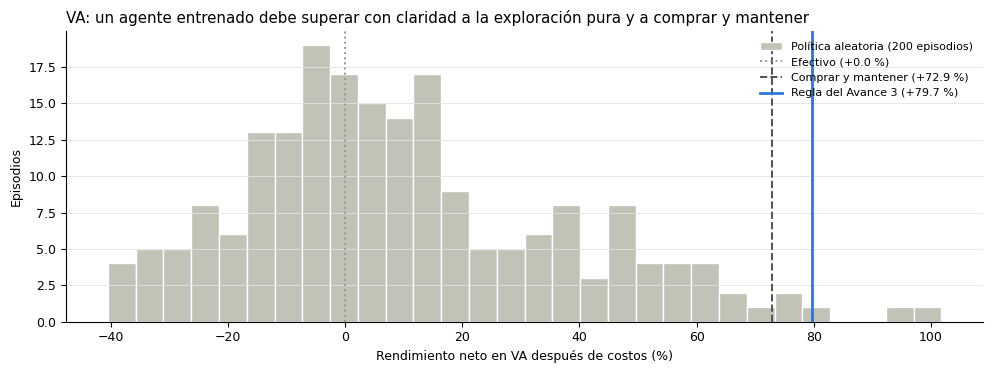

In [23]:
# === 6.1 Gráfica: distribución de la política aleatoria frente a las referencias ===
TINTA2, AZUL, NARANJA, GRIS, REJILLA = '#52514e', '#2a78d6', '#eb6834', '#9a9893', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': REJILLA, 'grid.linewidth': 0.6, 'font.size': 9})
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(100 * ALEA['rendimiento_neto'], bins=30, color='#c3c2b7', edgecolor='white', label=f'Política aleatoria ({len(ALEA)} episodios)')
for (nombre, color, estilo) in [('Efectivo', GRIS, ':'), ('Comprar y mantener', TINTA2, '--')]:
    val = 100 * REFS.loc[REFS.politica == nombre, 'rendimiento_neto'].iloc[0]
    ax.axvline(val, color=color, ls=estilo, lw=1.4, label=f'{nombre} ({val:+.1f} %)')
val = 100 * REFS.loc[2, 'rendimiento_neto']
ax.axvline(val, color=AZUL, lw=2, label=f'Regla del Avance 3 ({val:+.1f} %)')
ax.set_xlabel('Rendimiento neto en VA después de costos (%)'); ax.set_ylabel('Episodios')
ax.set_title('VA: un agente entrenado debe superar con claridad a la exploración pura y a comprar y mantener', loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap10_referencias_VA.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Seguimiento: ¿podría el agente aprovechar un error del simulador para recibir una recompensa indebida?

Un agente de RL maximiza la recompensa **tal como está programada**. Si el simulador tiene un hueco, el agente lo encontrará antes que cualquier patrón real del mercado (*reward hacking*). Por eso cada hueco posible se prueba con un ataque deliberado. Cada prueba intenta obtener una ganancia que no sería alcanzable en la realidad y verifica que el entorno lo impide.

In [24]:
# === 7. Pruebas de abuso del entorno ===
ABUSOS = []
def abuso(nombre, riesgo, prueba):
    try:
        ok, detalle = prueba()
    except Exception as ex:          # se reporta cualquier excepción inesperada como fallo de la prueba
        ok, detalle = False, f'{type(ex).__name__}: {ex}'
    ABUSOS.append({'intento_de_abuso': nombre, 'riesgo_si_no_se_controla': riesgo, 'resultado': 'bloqueado' if ok else 'VULNERABLE',
                   'evidencia': detalle})
    registrar_evento('seguimiento cap10', nombre, riesgo[:80], 'prueba de abuso del entorno', 'bloqueado' if ok else 'VULNERABLE')

def _mirar_futuro():
    k = 50
    alt = PRECIOS.copy()
    futuro = alt.index > VA['fecha_emision'].iloc[k]
    alt.loc[futuro, ['open', 'close']] *= 3.0                    # se altera todo lo posterior al cierre de t
    env_a, env_b = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA'), EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA', precios=alt)
    ea, eb = env_a.reset(), env_b.reset()
    for _ in range(k):
        a = politica_regla(ea)
        ea, *_ = env_a.step(a)
        eb, *_ = env_b.step(a)
    iguales = all(np.isclose(ea[c], eb[c]) for c in CAMPOS_ESTADO)
    sin_futuro = not any(c in ea for c in ('y', 'close_siguiente', 'fecha_objetivo'))
    return iguales and sin_futuro, f'triplicar precios posteriores a {ea["fecha_decision"]} no cambia s_t; el estado no contiene y_t ni P_(t+1)'
abuso('Mirar el futuro', 'Recompensas imposibles al conocer P_(t+1) antes de decidir', _mirar_futuro)

def _operar_gratis():
    alterna = lambda e, env: VENDER if e['en_posicion'] else COMPRAR
    env_c = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA')
    env_0 = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA', costo=0.0)
    rc, _ = ejecutar_episodio(env_c, alterna)
    r0, _ = ejecutar_episodio(env_0, alterna)
    return rc['costos_totales'] > 0 and rc['rendimiento_neto'] < r0['rendimiento_neto'], \
        f"comprar/vender a diario: {rc['operaciones_cerradas']} operaciones, costos {rc['costos_totales']:,.0f} USDT; neto {rc['rendimiento_neto']:+.1%} vs {r0['rendimiento_neto']:+.1%} sin costos"
abuso('Operar sin pagar costos', 'Sobreoperar sin castigo; ganancias que desaparecen con comisiones', _operar_gratis)

def _doble_compra():
    env = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA')
    env.reset(); env.step(COMPRAR)
    u = env.unidades
    _, r, _, info = env.step(COMPRAR)
    return info['accion_invalida'] and env.unidades == u and info['costo'] == 0, \
        f'COMPRAR estando en posición se rechaza: unidades {u:.6f} → {env.unidades:.6f}, sin costo, inválidas = {env.invalidas}'
abuso('Comprar dos veces (apalancamiento)', 'Exposición mayor al 100 % del capital', _doble_compra)

def _venta_corto():
    env = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA')
    env.reset()
    _, r, _, info = env.step(VENDER)
    return info['accion_invalida'] and env.unidades == 0 and env.efectivo == env.capital, \
        f'VENDER sin posición se rechaza: unidades {env.unidades}, efectivo {env.efectivo:,.2f}, recompensa {r:+.2%}'
abuso('Vender en corto', 'Ganar con caídas usando una posición negativa no permitida', _venta_corto)

def _comprar_de_mas():
    env = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA')
    env.reset()
    ef = env.efectivo
    _, _, _, info = env.step(COMPRAR)
    gastado = env.unidades * env.apertura_ejec[0] + info['costo']
    return np.isclose(gastado, ef) and env.efectivo >= 0, f'monto + costo = {gastado:,.2f} = efectivo inicial {ef:,.2f}; efectivo restante {env.efectivo:.2f}'
abuso('Comprar más que el efectivo', 'Comprar sin dinero suficiente (efectivo negativo)', _comprar_de_mas)

def _precio_de_ayer():
    env = EntornoTrading(VA, PRED8[RED_PRINCIPAL]['VA'], 'VA')
    env.reset()
    _, _, _, info = env.step(COMPRAR)
    fecha_ok = info['fecha_ejecucion'] > info['fecha_decision']
    precio_ok = np.isclose(info['precio_ejecucion'], PRECIOS.loc[pd.Timestamp(info['fecha_ejecucion']), 'open'])
    return fecha_ok and precio_ok, f"decisión {info['fecha_decision']} (cierre), ejecución {info['fecha_ejecucion']} a la apertura {info['precio_ejecucion']:,.2f}"
abuso('Ejecutar al precio con el que se decidió', 'Ganancias que todavía no podían obtenerse', _precio_de_ayer)

def _evitar_costo_final():
    r, h = ejecutar_episodio(ENV_VA, politica_comprar_y_mantener)
    ult = h.iloc[-1]
    return ult['costo_liquidacion_final'] > 0 and ult['posicion_unidades'] == 0, \
        f"al final se liquida al cierre y se cobra {ult['costo_liquidacion_final']:,.2f} USDT dentro de la última recompensa"
abuso('No pagar la venta final', 'Rendimiento inflado por terminar con posición abierta', _evitar_costo_final)

def _saltar_huecos():
    if len(SEG_TR) < 2:
        return True, 'TR no tiene días faltantes; la validación existe igual'
    try:
        EntornoTrading(TR, PRED8[RED_PRINCIPAL]['TR'], 'TR')
    except EpisodioDiscontinuoError as ex:
        return True, f'un episodio sobre TR completo se rechaza ({len(SEG_TR)} tramos): {ex}'
    return False, 'se aceptó un episodio con días faltantes'
abuso('Cruzar días faltantes', 'Una recompensa de varios días contada como si fuera de uno', _saltar_huecos)

def _recompensa_inflada():
    rng2 = np.random.default_rng(7)
    pol = lambda e, env: rng2.choice(env.acciones_validas())
    oks = []
    for _ in range(20):
        r, _ = ejecutar_episodio(ENV_VA, pol)
        oks.append(np.isclose(r['prod_1_mas_R'], r['patrimonio_final'] / ENV_VA.capital, rtol=1e-10))
    return all(oks), 'en 20 episodios aleatorios, ∏(1+R) = W_final / W_0: la recompensa no cuenta dos veces ni omite costos'
abuso('Inflar la recompensa acumulada', 'Recompensas que no corresponden al patrimonio real', _recompensa_inflada)

def _usar_te():
    try:
        EntornoTrading(TE, np.zeros(len(TE)), 'TE')
    except FugaInformacionError as ex:
        return True, str(ex)
    return False, 'se creó un episodio con TE'
abuso('Entrenar o elegir con TE', 'Resultados finales optimistas por fuga de información', _usar_te)

def _seguir_despues_del_final():
    env = EntornoTrading(VA.iloc[:3], PRED8[RED_PRINCIPAL]['VA'][:3], 'VA')
    ejecutar_episodio(env, politica_efectivo)
    try:
        env.step(MANTENER)
    except ErrorPractica as ex:
        return True, str(ex)
    return False, 'se aceptaron pasos tras el final'
abuso('Seguir operando después del final', 'Recompensas fuera del periodo', _seguir_despues_del_final)

ABUSOS_DF = pd.DataFrame(ABUSOS)
ABUSOS_DF.to_csv(DIRS['resultados'] / 'pruebas_abuso_entorno_cap10.csv', index=False)
print(f"{(ABUSOS_DF.resultado == 'bloqueado').sum()} de {len(ABUSOS_DF)} intentos de abuso bloqueados.")
if (ABUSOS_DF.resultado != 'bloqueado').any():
    raise ValorInvalidoError('El entorno tiene al menos una vulnerabilidad: corregir antes de entrenar un agente.')
ABUSOS_DF

[BITÁCORA] seguimiento cap10 | Mirar el futuro | Recompensas imposibles al conocer P_(t+1) antes de decidir | prueba de abuso del entorno | bloqueado
[BITÁCORA] seguimiento cap10 | Operar sin pagar costos | Sobreoperar sin castigo; ganancias que desaparecen con comisiones | prueba de abuso del entorno | bloqueado
[BITÁCORA] seguimiento cap10 | Comprar dos veces (apalancamiento) | Exposición mayor al 100 % del capital | prueba de abuso del entorno | bloqueado
[BITÁCORA] seguimiento cap10 | Vender en corto | Ganar con caídas usando una posición negativa no permitida | prueba de abuso del entorno | bloqueado
[BITÁCORA] seguimiento cap10 | Comprar más que el efectivo | Comprar sin dinero suficiente (efectivo negativo) | prueba de abuso del entorno | bloqueado
[BITÁCORA] seguimiento cap10 | Ejecutar al precio con el que se decidió | Ganancias que todavía no podían obtenerse | prueba de abuso del entorno | bloqueado
[BITÁCORA] seguimiento cap10 | No pagar la venta final | Rendimiento inflado

,intento_de_abuso,riesgo_si_no_se_controla,resultado,evidencia
0,Mirar el futuro,Recompensas imposibles al conocer P_(t+1) antes de decidir,bloqueado,triplicar precios posteriores a 2024-07-21 no cambia s_t; el estado no conti...
1,Operar sin pagar costos,Sobreoperar sin castigo; ganancias que desaparecen con comisiones,bloqueado,"comprar/vender a diario: 221 operaciones, costos 44,505 USDT; neto -1.4% vs ..."
2,Comprar dos veces (apalancamiento),Exposición mayor al 100 % del capital,bloqueado,"COMPRAR estando en posición se rechaza: unidades 1.474174 → 1.474174, sin co..."
3,Vender en corto,Ganar con caídas usando una posición negativa no permitida,bloqueado,"VENDER sin posición se rechaza: unidades 0.0, efectivo 100,000.00, recompens..."
4,Comprar más que el efectivo,Comprar sin dinero suficiente (efectivo negativo),bloqueado,"monto + costo = 100,000.00 = efectivo inicial 100,000.00; efectivo restante ..."
5,Ejecutar al precio con el que se decidió,Ganancias que todavía no podían obtenerse,bloqueado,"decisión 2024-06-01 (cierre), ejecución 2024-06-02 a la apertura 67,766.84"
6,No pagar la venta final,Rendimiento inflado por terminar con posición abierta,bloqueado,al final se liquida al cierre y se cobra 173.08 USDT dentro de la última rec...
7,Cruzar días faltantes,Una recompensa de varios días contada como si fuera de uno,bloqueado,un episodio sobre TR completo se rechaza (2 tramos): El episodio cruza días ...
8,Inflar la recompensa acumulada,Recompensas que no corresponden al patrimonio real,bloqueado,"en 20 episodios aleatorios, ∏(1+R) = W_final / W_0: la recompensa no cuenta ..."
9,Entrenar o elegir con TE,Resultados finales optimistas por fuga de información,bloqueado,TE está reservado: no se construyen episodios con TE.


**Riesgos que el simulador todavía no cubre** (para la respuesta del seguimiento):
- **Ejecución perfecta en la apertura:** no hay deslizamiento (*slippage*) ni liquidez limitada. Un agente podría preferir operar en aperturas muy volátiles donde, en la realidad, el precio obtenido sería peor.
- **Costos fijos de 0.10 %:** son un supuesto académico. Si el costo real fuera mayor, una política entrenada para operar seguido perdería su ventaja.
- **Errores de datos:** un precio erróneo, como un pico aislado, sería una ganancia "gratis". La auditoría del Avance 1 retira precios no válidos y reporta incoherencias OHLC y valores extremos, pero no corrige picos plausibles.
- **Sesgo hacia comprar y mantener:** el libro advierte que una recompensa mal diseñada puede llevar a esa estrategia. Con la recompensa de patrimonio, en periodos alcistas el agente puede aprender a "siempre comprar". Por eso debe compararse con comprar y mantener en VA.

Conclusión: los huecos que permitirían una recompensa indebida directa (información futura, operar sin costo, apalancamiento, ventas en corto, ejecución al precio de decisión, evitar el costo final, cruzar huecos, inflar la recompensa y usar TE) están bloqueados y probados.

## 8. DQN y DDQN: exploración, memoria de experiencias y red objetivo

**Q-learning (capítulo 10).** El valor $Q(s,a)$ estima la recompensa acumulada esperada al tomar la acción $a$ en el estado $s$ y seguir la política después. Se actualiza con la ecuación de Bellman:
$$Q(s_t,a_t) \leftarrow R_{t+1} + \gamma \max_{a'} Q(s_{t+1}, a').$$

> **Nota sobre el libro:** el capítulo 10 llama a γ "tasa de aprendizaje", pero en su propia advertencia lo describe correctamente como el **factor de descuento**, que indica cuánto pesan las recompensas futuras. La **tasa de aprendizaje** $\alpha$ es otra cosa: el tamaño del paso con que se ajustan los valores o los pesos de la red. Aquí se usa γ = 0.99 como factor de descuento.

**DQN.** Como el estado tiene 24 variables continuas, no cabe en una tabla Q. Una red neuronal aproxima $Q(s,\cdot)$ con 3 salidas, una por acción. Tiene tres piezas:
- **Exploración ε-greedy:** con probabilidad ε elige una acción **válida** al azar (explorar); si no, la de mayor $Q$ (explotar). ε empieza en 1 y decae hasta 0.05.
- **Memoria de experiencias (*replay memory*):** guarda transiciones $(s, a, R, s', \text{fin})$ y entrena con **lotes aleatorios** de esa memoria. Eso rompe la correlación entre días consecutivos y reutiliza experiencias.
- **Red objetivo:** una copia de la red que se **congela** y se sincroniza cada cierto número de pasos. Calcula el objetivo $y = R + \gamma \max_{a'} Q_{\text{obj}}(s',a')$ para que no se persiga un blanco que se mueve con cada actualización.

**DDQN.** El máximo de DQN tiende a **sobreestimar** los valores, porque elige y evalúa la acción con la misma red. DDQN **separa la selección de la evaluación**: la red en línea elige $a^* = \arg\max_{a'} Q_{\text{línea}}(s',a')$ y la red objetivo la evalúa:
$$y = R + \gamma\, Q_{\text{obj}}\big(s', \arg\max_{a'} Q_{\text{línea}}(s',a')\big).$$

En ambos casos, en $s'$ solo se consideran las acciones **válidas** (máscara) y, si $s'$ es terminal, $y = R$.

La celda siguiente **no entrena al agente**: llena la memoria con exploración pura sobre TR, toma un lote y calcula los objetivos de DQN y DDQN recién sincronizadas las dos redes y después de **200 pasos de gradiente ilustrativos** de la red en línea, con la red objetivo congelada. Así se ve que los dos objetivos empiezan iguales, se separan cuando las redes prefieren acciones distintas y que el de DDQN nunca es mayor que el de DQN.

In [25]:
# === 8. Demostración de piezas de DQN/DDQN (sin entrenar al agente) ===
from collections import deque

class MemoriaExperiencias:
    def __init__(self, capacidad, semilla):
        self.buffer, self.rng = deque(maxlen=capacidad), np.random.default_rng(semilla)
    def guardar(self, s, a, r, s2, fin, mascara2):
        self.buffer.append((s, a, r, s2, fin, mascara2))
    def muestrear(self, n):
        if len(self.buffer) < n:
            raise DatosVaciosError(f'La memoria tiene {len(self.buffer)} experiencias; se pidieron {n}.')
        idx = self.rng.choice(len(self.buffer), size=n, replace=False)      # muestreo aleatorio: rompe la correlación temporal
        s, a, r, s2, fin, m2 = zip(*(self.buffer[i] for i in idx))
        return np.array(s), np.array(a), np.array(r, dtype='float32'), np.array(s2), np.array(fin, dtype='float32'), np.array(m2)

def mascara(env):
    m = np.zeros(3, dtype=bool)
    if not env.terminado:
        m[env.acciones_validas()] = True
    return m

def epsilon_greedy(q, validas, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.choice(validas)), 'exploración'
    q_val = np.full(3, -np.inf); q_val[validas] = q[validas]
    return int(np.argmax(q_val)), 'explotación'

eps0, eps_min, decai = CONFIG['DQN_EPSILON']
print('Decaimiento propuesto de ε por paso:', {p: round(max(eps_min, eps0 * decai ** p), 3) for p in (0, 100, 500, 1000, 2000)})

# Llenar la memoria con exploración pura (ε = 1) recorriendo los tramos contiguos de TR
rng_dqn = np.random.default_rng(SEMILLA)
memoria = MemoriaExperiencias(CONFIG['DQN_MEMORIA'], SEMILLA)
for seg in SEG_TR:
    idx = TR.index[TR['fecha_emision'].isin(seg['fecha_emision'])]
    env = EntornoTrading(seg, PRED8[RED_PRINCIPAL]['TR'][idx], 'TR')
    e, fin = env.reset(), False
    while not fin:
        a, _ = epsilon_greedy(np.zeros(3), env.acciones_validas(), 1.0, rng_dqn)
        s = vector_estado(e)
        e, r, fin, _ = env.step(a)
        memoria.guardar(s, a, r, vector_estado(e), fin, mascara(env))
print(f'Memoria de experiencias: {len(memoria.buffer)} transiciones de TR (capacidad {CONFIG["DQN_MEMORIA"]})')

def red_q():
    keras.utils.set_random_seed(SEMILLA)
    entrada = keras.Input(shape=(len(CAMPOS_ESTADO),))
    x = layers.Dense(32, activation='relu')(entrada)
    x = layers.Dense(32, activation='relu')(x)
    m = keras.Model(entrada, layers.Dense(3)(x))
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
    return m
with tf.device(DISPOSITIVO):
    q_linea, q_obj = red_q(), red_q()
    q_obj.set_weights(q_linea.get_weights())             # sincronización: la red objetivo es una copia congelada

def objetivos(s2, r, fin, m2, gamma=CONFIG['DQN_GAMMA']):
    q2_obj = np.asarray(q_obj(s2, training=False))
    q2_lin = np.asarray(q_linea(s2, training=False))
    q2_obj_m = np.where(m2, q2_obj, -np.inf)
    q2_lin_m = np.where(m2, q2_lin, -np.inf)
    max_obj = np.where(fin == 1, 0.0, q2_obj_m.max(axis=1))
    a_star = q2_lin_m.argmax(axis=1)                                      # DDQN: la red en línea elige…
    eval_obj = np.where(fin == 1, 0.0, q2_obj[np.arange(len(r)), a_star])   # …la red objetivo evalúa
    return r + gamma * max_obj, r + gamma * eval_obj

s, a, r, s2, fin, m2 = memoria.muestrear(CONFIG['DQN_LOTE'])
y_dqn0, y_ddqn0 = objetivos(s2, r, fin, m2)
PASOS_DEMO = 200
perdidas = []
with tf.device(DISPOSITIVO):        # pasos de gradiente ilustrativos de la red en línea; la red objetivo sigue congelada
    for _ in range(PASOS_DEMO):
        sb, ab, rb, s2b, finb, m2b = memoria.muestrear(CONFIG['DQN_LOTE'])
        yb, _ = objetivos(s2b, rb, finb, m2b)
        q_pred = np.asarray(q_linea(sb, training=False)).copy()
        q_pred[np.arange(len(ab)), ab] = yb
        perdidas.append(float(q_linea.train_on_batch(sb, q_pred)))
y_dqn1, y_ddqn1 = objetivos(s2, r, fin, m2)
distintos = ~np.isclose(y_dqn1, y_ddqn1, rtol=1e-6, atol=1e-9)
DEMO = pd.DataFrame({'accion': [NOMBRE_ACCION[x] for x in a[:8]], 'recompensa': r[:8],
                     'y_DQN (sincronizadas)': y_dqn0[:8], 'y_DDQN (sincronizadas)': y_ddqn0[:8],
                     f'y_DQN (tras {PASOS_DEMO} pasos)': y_dqn1[:8], f'y_DDQN (tras {PASOS_DEMO} pasos)': y_ddqn1[:8]})
print(f'Recién sincronizadas, DQN y DDQN dan el mismo objetivo: {np.allclose(y_dqn0, y_ddqn0)}')
print(f'Tras {PASOS_DEMO} pasos de la red en línea (pérdida {perdidas[0]:.2e} → {perdidas[-1]:.2e}) con la red objetivo congelada:')
print(f'  los objetivos difieren en {distintos.mean():.0%} del lote; y_DDQN ≤ y_DQN en todos los casos: {bool(np.all(y_ddqn1 <= y_dqn1 + 1e-12))}')
print(f'  en promedio, DDQN reduce el objetivo en {np.mean(y_dqn1 - y_ddqn1):.2e} (la sobreestimación que corrige)')
print('  Difieren solo cuando la red en línea y la red objetivo prefieren acciones distintas en s\'.')
print('Esto no es entrenar al agente: no hay ciclo de episodios, ni política evaluada, ni selección de hiperparámetros.')
DEMO.round(6)

Decaimiento propuesto de ε por paso: {0: 1.0, 100: 0.606, 500: 0.082, 1000: 0.05, 2000: 0.05}
Memoria de experiencias: 2067 transiciones de TR (capacidad 10000)
Recién sincronizadas, DQN y DDQN dan el mismo objetivo: True
Tras 200 pasos de la red en línea (pérdida 2.98e-01 → 6.34e-02) con la red objetivo congelada:
  los objetivos difieren en 53% del lote; y_DDQN ≤ y_DQN en todos los casos: True
  en promedio, DDQN reduce el objetivo en 4.00e-01 (la sobreestimación que corrige)
  Difieren solo cuando la red en línea y la red objetivo prefieren acciones distintas en s'.
Esto no es entrenar al agente: no hay ciclo de episodios, ni política evaluada, ni selección de hiperparámetros.


,accion,recompensa,y_DQN (sincronizadas),y_DDQN (sincronizadas),y_DQN (tras 200 pasos),y_DDQN (tras 200 pasos)
0,MANTENER,-0.021830,0.455183,0.455183,0.455183,-0.688837
1,MANTENER,0.000000,0.501881,0.501881,0.501881,0.501881
2,MANTENER,0.000000,0.602266,0.602266,0.602266,0.602266
3,MANTENER,0.000000,0.727555,0.727555,0.727555,-0.097057
4,VENDER,-0.001000,0.408498,0.408498,0.408498,0.408498
5,VENDER,-0.001000,0.854851,0.854851,0.854851,0.854851
6,MANTENER,0.000000,0.337898,0.337898,0.337898,0.337898
7,COMPRAR,0.039306,0.375806,0.375806,0.375806,0.089206


## 9. Especificación exportada y controles finales

In [26]:
# === 9. Especificación del entorno (archivo) y controles ===
ESPEC = {
    'activo': f"{CONFIG['MONEDA_BASE']}/{CONFIG['MONEDA_COTIZADA']} diario (MEXC spot)",
    'momento_de_decision': 'cierre del día t',
    'estado': {'variables': CAMPOS_ESTADO, 'rendimientos_recientes': 'r_t … r_{t-19}, r_t = P_t/P_{t-1} − 1',
               'pronostico': f'ensamble {RED_PRINCIPAL.upper()} ({MEJOR_N[RED_PRINCIPAL]} neuronas, semillas {SEMILLAS}) con los mismos 20 rendimientos',
               'volatilidad': 'desviación estándar muestral de r_t … r_{t-19}', 'cartera': 'fracción en efectivo y posición (0/1)',
               'normalizacion_para_red': 'rezagos con el escalador de TR; pronóstico y volatilidad con media y desv. de TR',
               'informacion_disponible': 'solo hasta el cierre de t'},
    'acciones': {'COMPRAR': 'efectivo → 100 % BTC', 'MANTENER': 'en posición: mantener la posición; en efectivo: permanecer en efectivo',
                 'VENDER': 'cerrar la posición existente → efectivo', 'validas_en_efectivo': ['COMPRAR', 'MANTENER'],
                 'validas_en_posicion': ['MANTENER', 'VENDER'], 'accion_invalida': 'se rechaza y se ejecuta MANTENER; se registra'},
    'restricciones': ['sin apalancamiento', 'sin posiciones negativas', 'monto + costo ≤ efectivo disponible', 'solo se vende lo que se tiene'],
    'ejecucion': 'apertura de t+1', 'costos': f"{CONFIG['COSTO']:.2%} por compra y por venta, solo cuando cambia la posición",
    'recompensa': {'formula': 'R_{t+1} = W_{t+1}/W_t − 1, W = efectivo + unidades × cierre (después de costos)',
                   'momento': 'al cierre de t+1, asignada a (s_t, a_t)',
                   'fin_de_episodio': 'liquidación al último cierre con costo de venta incluido en la última recompensa'},
    'episodios': {'entrenamiento': f'TR en {len(SEG_TR)} tramos contiguos', 'seleccion': 'VA (1 tramo)', 'TE': 'reservado; el entorno lo rechaza'},
    'capital_inicial': CONFIG['CAPITAL_INICIAL'],
    'dqn_propuesto': {'gamma_descuento': CONFIG['DQN_GAMMA'], 'epsilon_inicial_minimo_decaimiento': CONFIG['DQN_EPSILON'],
                      'memoria': CONFIG['DQN_MEMORIA'], 'lote': CONFIG['DQN_LOTE'], 'sincronizar_objetivo_cada': CONFIG['DQN_SINCRONIZAR_CADA'],
                      'red': f'{len(CAMPOS_ESTADO)} → Dense(32, ReLU) → Dense(32, ReLU) → 3 valores Q', 'variante': 'DDQN con máscara de acciones válidas'},
    'referencias_VA': REFS[['politica', 'rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'costos_totales']].to_dict('records'),
    'fecha_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'especificacion_entorno_cap10.json', 'w') as f:
    json.dump(ESPEC, f, indent=2, ensure_ascii=False, default=float)

controles = {
    'Evidencia T4 registrada': bool(EVIDENCIA_T4.get('T4_OK')),
    'Entorno = simulador del Avance 3 (regla, comprar y mantener, efectivo)': bool(EQUIV['coincide'].all()),
    'Transición manual = entorno (compra y venta)': True,
    'Intentos de abuso bloqueados': f"{(ABUSOS_DF.resultado == 'bloqueado').sum()} de {len(ABUSOS_DF)}",
    'Estado sin información futura': ABUSOS_DF.loc[ABUSOS_DF.intento_de_abuso == 'Mirar el futuro', 'resultado'].iloc[0] == 'bloqueado',
    'Costos contabilizados en cada cambio de posición y al final': all(ABUSOS_DF.loc[ABUSOS_DF.intento_de_abuso.isin(
        ['Operar sin pagar costos', 'No pagar la venta final']), 'resultado'] == 'bloqueado'),
    'Conjuntos sobre los que se predijo': ', '.join(sorted(CONJUNTOS_PREDICHOS)),
    'TE no se usó': 'TE' not in CONJUNTOS_PREDICHOS,
}
for k, v in controles.items():
    print(('✔' if v is True else '✘' if v is False else '•'), k, '' if isinstance(v, bool) else f': {v}')
with open(DIRS['resultados'] / 'controles_cap10.json', 'w') as f:
    json.dump(controles, f, indent=2, ensure_ascii=False, default=str)

✔ Evidencia T4 registrada 
✔ Entorno = simulador del Avance 3 (regla, comprar y mantener, efectivo) 
✔ Transición manual = entorno (compra y venta) 
• Intentos de abuso bloqueados : 11 de 11
✔ Estado sin información futura 
✔ Costos contabilizados en cada cambio de posición y al final 
• Conjuntos sobre los que se predijo : TR, VA
✔ TE no se usó 


## Pronóstico, señal y política aprendida

- El **pronóstico** ŷ es solo un número estimado y no decide nada.
- La **señal** es una regla fija escrita por ustedes (“comprar si ŷ > δ”) que dice dónde estar.
- La **política aprendida** π(s) la aprende el agente por prueba y error con el estado completo. Por ejemplo, puede aprender a no vender por una señal débil cuando el costo no lo justifica.
- En el notebook se ve que la misma señal de “comprar” genera `COMPRAR` si se está en efectivo y `MANTENER` si ya se está en posición.

## DQN y DDQN

- **Exploración (ε-greedy):** con probabilidad ε elige una acción válida al azar; si no, elige la de mayor valor Q. ε baja de 1 a 0.05.
- **Memoria de experiencias:** guarda transiciones (s, a, R, s’, fin) y entrena con lotes aleatorios, lo que rompe la correlación entre días consecutivos.
- **Red objetivo:** una copia congelada que se sincroniza cada cierto número de pasos para estabilizar el blanco.
- **DDQN:** la red en línea elige la acción y la red objetivo la evalúa. Así reduce la sobreestimación; la demostración del notebook muestra que su objetivo nunca es mayor que el de DQN.
- **Nota sobre el libro:** el capítulo 10 llama a γ “tasa de aprendizaje”, pero es el **factor de descuento**.

## Seguimiento: ¿el agente podría aprovechar un error del simulador?

Sí. Un agente de RL explota cualquier hueco antes que cualquier patrón real (*reward hacking*). Por eso se atacó el entorno a propósito, y quedaron bloqueados estos intentos:

- Mirar el futuro (se triplican los precios posteriores a t y el estado no cambia).
- Operar sin costo.
- Comprar dos veces.
- Vender en corto.
- Comprar más que el efectivo.
- Ejecutar al precio con el que se decidió.
- No pagar la venta final.
- Cruzar días faltantes.
- Inflar la recompensa (se verifica que ∏(1+R) = W_final/W₀).
- Usar TE.
- Seguir operando después del final.

Los riesgos que **siguen abiertos** también van en la respuesta:

- No se modela deslizamiento ni liquidez.
- El costo de 0.10 % es un supuesto académico.
- Un pico de precio erróneo pero plausible sería una ganancia regalada.
- La recompensa de patrimonio puede sesgar al agente hacia comprar y mantener en periodos alcistas.

## Información futura y costos

Las pruebas de “mirar el futuro”, “operar sin costo” y “no pagar la venta final” son la evidencia que pide la hoja.

## 10. Preguntas del capítulo 10

Esta sección es un borrador para el informe. Llénenla o bórrenla antes de entregar; no la dejen con "…".

- **Qué hicimos:** …
- **Por qué:** …
- **Evidencia obtenida:** (especificación, equivalencia con el simulador, transición manual, referencias, pruebas de abuso) …
- **Diferencia entre pronóstico, señal y política aprendida:** …
- **¿El agente podría aprovechar un error del simulador?** …
- **Qué cambiaríamos después:** (capítulo 11: indicadores en el estado; entrenamiento de DDQN con TR, selección con VA y una prueba nueva independiente) …